# Modelagem Computacional da Propagação Bidimensional de Trincas por Fadiga via Dual-BEM (`Fracture 2D`)
## Guia Didático Passo a Passo: Do Gmsh (`.geo`) e `meshio` ao Solver Fortran 90 com Elementos Quadráticos Descontínuos

Este Jupyter Notebook apresenta o fluxo completo (**pipeline**) para modelagem geométrica e geração de malha com o **Gmsh**, conversão para **elementos quadráticos descontínuos** via **`meshio`**, compilação e execução do solver em Fortran 90 **`fracture_2d`**, e pós-processamento gráfico dos resultados.

Este notebook é **multiplataforma** e foi projetado para executar tanto **localmente (Windows / Linux / macOS)** quanto no **Google Colab (Ubuntu Linux com aceleração multithread OpenMP)**.

---
### Dissertação de Referência:
> **Beatriz Borges Faria Fonseca** (UFMG, 2023),  
> *Modelagem computacional da propagação bidimensional de trincas por fadiga utilizando o Método dos Elementos de Contorno Dual.*  
> Arquivo no repositório: `DissertaçãoBeatrizFonseca.pdf`

### Arquitetura do Novo Framework Didático (4 Etapas):
1. **Modelagem Paramétrica no Gmsh (`meshes/*.geo` $\to$ `.msh`)**:
   - O contorno externo da peça e as trincas iniciais são modelados em scripts `.geo` com grupos físicos (`Physical Curve`) nomeados.
   - O Gmsh gera uma malha 1D curvilínea de segunda ordem (`line3`, elementos quadráticos contínuos de 3 nós).
2. **Pré-processamento e Conversão para Elementos Descontínuos (`input_data.py` + `preproc.py`)**:
   - Como o Gmsh gera elementos contínuos, o script `preproc.py` lê o arquivo `.msh` usando **`meshio`** e converte **todos os elementos** (do contorno externo e das trincas) em **elementos quadráticos descontínuos de 3 nós** ($\lambda_1 = \lambda_2 = 2/3$, com nós funcionais em $\xi \in \{-2/3, 0, +2/3\}$).
   - Cada curva física de trinca é automaticamente duplicada com orientações opostas para formar as duas faces coincidentes do **Dual-BEM**:
     - **Face 1 (`bie = 2`)**: Equação Integral de Contorno (EIC) Singular de Deslocamentos;
     - **Face 2 (`bie = 3`)**: Equação Integral de Contorno (EIC) Hipersingular de Trações;
     - **Contorno externo (`bie = 1`)**: EIC Singular de Deslocamentos.
3. **Solver Fortran 90 Exclusivamente com Elementos Descontínuos (`src/*.f90` $\to$ `bin/fracture_2d.exe`)**:
   - Como cada nó pertence a um único elemento ($N_{\text{nós}} = 3 N_{\text{elem}}$), eliminam-se completamente ambiguidades de vetor normal em quinas e conflitos de condições de contorno em vértices.
   - Integração regular por Gauss-Legendre, fracamente singular por Gauss-Laguerre e forte/hipersingular pelo **Método da Expansão Radial de Gao**.
   - Cálculo de $K_I$ e $K_{II}$ por **Correlação de Deslocamentos** ou **Integral $J$ desacoplada** em contorno circular, direção pelo critério da **Máxima Tensão Circunferencial (MTC)** com correção iterativa de **Portela**, e vida em fadiga por **Paris-Walker** e **Rainflow**.
4. **Pós-processamento e Visualização (`plot_mesh_bc.py` + `plot_results.py`)**:
   - Reprodução automática das **Figuras 5.26 a 5.30** da dissertação (trajetória da trinca, malha final, deformada ampliada 40x, vida em fadiga $N \times \Delta a$, taxa $da/dN \times \Delta K$ e evolução de $K_I, K_{II}, K_{\text{eq}}$).

## 0. Preparação do Ambiente (Google Colab e Ambiente Local)

Esta célula detecta automaticamente o ambiente de execução:
- **No Google Colab (Linux)**: instala o compilador `gfortran`, as bibliotecas `liblapack-dev` e `libblas-dev`, o `gmsh` e os pacotes Python necessários.
- **No Ambiente Local (Windows / Linux)**: verifica e instala eventuais pacotes Python ausentes (`numpy`, `matplotlib`, `meshio`, `gmsh`).

In [1]:
import os
import sys
import subprocess
import importlib

# 1. Detecção do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[*] Ambiente Google Colab detectado!")
    print("[*] Instalando compilador gfortran, bibliotecas LAPACK/BLAS e Gmsh no Linux...")
    try:
        subprocess.run(
            "apt-get update -qq && apt-get install -y -qq gfortran liblapack-dev libblas-dev gmsh make",
            shell=True, check=True
        )
        print("[+] Ferramentas de sistema instaladas com sucesso no Colab!")
    except Exception as e:
        print(f"[!] Aviso ao instalar pacotes apt: {e}")

# 2. Verificação de pacotes Python necessários
required_packages = ['numpy', 'matplotlib', 'meshio', 'gmsh']

missing_packages = []
for pkg in required_packages:
    try:
        importlib.import_module(pkg)
    except ImportError:
        missing_packages.append(pkg)

if missing_packages:
    print(f"[*] Instalando pacotes Python ausentes ({missing_packages})...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing_packages])
    importlib.invalidate_caches()
    print("[+] Pacotes Python instalados com sucesso!")
else:
    print(f"[+] Todos os pacotes necessários ({required_packages}) já estão disponíveis.")

[+] Todos os pacotes necessários (['numpy', 'matplotlib', 'meshio', 'gmsh']) já estão disponíveis.


## 1. Configuração do Ambiente e Importação dos Módulos do Projeto

Configuramos o `PATH` do sistema para que o compilador Fortran (`gfortran`) e o `mingw32-make` (no Windows via MSYS2 UCRT64) estejam acessíveis, e importamos os módulos Python do projeto:
- `input_data.py`: função `input_data(problem)` que retorna os dicionários dos 8 problemas de validação da dissertação;
- `preproc.py`: função `run_preproc(problem)` que executa o Gmsh (`.geo` $\to$ `.msh`), lê a malha com `meshio` e gera o arquivo `.dat` com elementos quadráticos descontínuos;
- `plot_mesh_bc.py`: visualização da malha descontínua, faces da trinca e condições de contorno;
- `plot_results.py`: pós-processamento gráfico completo dos resultados de propagação e fadiga.

In [2]:
import shutil
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import meshio
import gmsh
from IPython.display import Image, display

# No Windows, adiciona MinGW-w64 (MSYS2 UCRT64) ao início do PATH para o gfortran
if os.name == 'nt':
    ucrt64_bin = "C:/msys64/ucrt64/bin"
    python_scripts = os.path.join(os.path.dirname(sys.executable), "Scripts")
    for p in [ucrt64_bin, python_scripts]:
        if os.path.exists(p) and p not in os.environ["PATH"]:
            os.environ["PATH"] = p + os.pathsep + os.environ["PATH"]

# Garante que o diretório raiz do projeto esteja no sys.path
ROOT_DIR = Path(os.getcwd()).resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

from input_data import input_data
from preproc import run_preproc
import plot_results

print("Ambiente configurado com sucesso!")
print(f"Sistema Operacional : {sys.platform} ({os.name})")
print(f"Diretório do projeto: {ROOT_DIR}")
print("\nProblemas de validação disponíveis em input_data.py (1 a 8):")
for pid in range(1, 9):
    cfg = input_data(pid)
    print(f"  [{pid}] {cfg['analysis_id']:<28s} : {cfg['title']} (meshes/{cfg['file_name']}.geo)")

Ambiente configurado com sucesso!
Sistema Operacional : win32 (nt)
Diretório do projeto: C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D

Problemas de validação disponíveis em input_data.py (1 a 8):
  [1] Chambers_CMM_4               : Compact Mixed Mode Specimen CMM4 (alpha=110 deg, theta=-4 deg) (meshes/chambers_cmm4.geo)
  [2] Dowling_11.6_variable_ampl   : Central Cracked Plate under Variable Amplitude Loading (Dowling 11.6) (meshes/dowling_11_6.geo)
  [3] s521_single_edge             : Single Edge Cracked Plate AISI 4340 (Sec. 5.2.1) (meshes/s521_single_edge.geo)
  [4] s522_double_edge             : Double Edge Cracked Plate AISI 4340 (Sec. 5.2.2) (meshes/s522_double_edge.geo)
  [5] s51_da0_01_r11               : Rectangular Plate 3x1 Central Crack Isida (da0_01_r11) (meshes/s51_internal_crack.geo)
  [6] s531_cmm_90                  : Compact Mixed Mode Specimen CMM1-3 (alpha=90 deg, theta=-3 deg) (meshes/chambers_cmm90.geo)
  [7] s3131_aw4                    : Squar

## 2. Como Construir a Geometria e a Malha no Gmsh (`meshes/*.geo`)

No Método dos Elementos de Contorno Dual (Dual-BEM) com **elementos quadráticos descontínuos**, apenas o **contorno 1D** do domínio e a **linha da trinca** precisam ser discretizados (`Line` e `Circle` no Gmsh), enquanto uma superfície auxiliar (`Plane Surface`) define o domínio para o Gmsh.

### Regras Fundamentais para Modelar uma Peça com Trinca no Gmsh:
1. **Sentido de percurso do contorno externo**:
   - Percorra o contorno externo no **sentido anti-horário** (para que o domínio fique à esquerda e o vetor normal aponte para fora).
2. **Trincas de borda (*edge cracks*)**:
   - Quando uma trinca nasce em uma aresta externa (por exemplo, na coordenada $(0, y_0)$), **divida a aresta externa exatamente no ponto de abertura da trinca** em dois segmentos separados. Como o pré-processador converte cada elemento em descontínuo ($\lambda_1 = \lambda_2 = 2/3$), nenhum nó funcional cairá exatamente sobre o vértice da boca da trinca!
3. **Grupos Físicos (`Physical Curve`)**:
   - Atribua um nome claro a cada trecho do contorno com condição de contorno distinta (ex.: `"bottom_roller"`, `"top_traction"`, `"free_boundary"`) e um grupo físico para cada trinca (ex.: `"crack"`).

Abaixo inspecionamos dois arquivos `.geo` do projeto:
- **Problema 3 (Modo I)**: `meshes/s521_single_edge.geo` — Placa retangular de aço AISI 4340 com uma trinca de borda (Seção 5.2.1 da dissertação);
- **Problema 1 (Modo Misto)**: `meshes/chambers_cmm4.geo` — Corpo de prova *Compact Mixed Mode* (CMM, $\alpha = 110^\circ$, Seção 5.3.2 da dissertação).

In [3]:
geo_s521 = (ROOT_DIR / "meshes" / "s521_single_edge.geo").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo: meshes/s521_single_edge.geo (Placa com 1 Trinca de Borda - Modo I)")
print("=" * 78)
print(geo_s521)

geo_cmm4 = (ROOT_DIR / "meshes" / "chambers_cmm4.geo").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo: meshes/chambers_cmm4.geo (Corpo de Prova CMM4 - Modo Misto 110°)")
print("=" * 78)
print(geo_cmm4)

 Arquivo: meshes/s521_single_edge.geo (Placa com 1 Trinca de Borda - Modo I)
// =============================================================================
// s521_single_edge.geo - Placa com Uma Trinca de Borda (Aço AISI 4340)
// Seção 5.2.1 da Dissertação (R = 1/3, sigma_max = 526 MPa, a0 = 2.0 mm)
// Dimensões: largura W = 0.076 m, altura H = 0.152 m
// =============================================================================

lc = 0.01;

// --- Vértices do Contorno Externo ---
// Nota: A aresta esquerda é dividida na boca da trinca (0, 0.076) e a aresta
// direita possui um segmento central engastado ao redor de y = 0.076 m para
// impedir movimento de corpo rígido sob tração simétrica superior/inferior.
Point(1) = {0.000, 0.000000, 0.0, lc};
Point(2) = {0.076, 0.000000, 0.0, lc};
Point(3) = {0.076, 0.073625, 0.0, lc};
Point(4) = {0.076, 0.078375, 0.0, lc};
Point(5) = {0.076, 0.152000, 0.0, lc};
Point(6) = {0.000, 0.152000, 0.0, lc};
Point(7) = {0.000, 0.076000, 0.0, lc}; // 

## 3. Como Definir Materiais, Condições de Contorno e Parâmetros de Fadiga (`input_data.py`)

No arquivo `input_data.py`, a função `input_data(problem)` retorna um dicionário Python legível contendo:
- **`E`, `nu`, `plane_state`**: Módulo de Young, coeficiente de Poisson e estado plano (`1` = Estado Plano de Tensões, `2` = Estado Plano de Deformações);
- **`npow`**: Número de termos da expansão polinomial radial de Gao para integrais fortes/hipersingulares;
- **`bound_cond`**: Dicionário que associa o nome de cada `Physical Curve` do contorno externo à sua condição de contorno:
  - `'type_x': 'ux'` (deslocamento prescrito `bck = 0`) ou `'tx'` (tração prescrita `bck = 1`), seguido de `'value_x'`;
  - `'type_y': 'uy'` (deslocamento prescrito `bck = 0`) ou `'ty'` (tração prescrita `bck = 1`), seguido de `'value_y'`;
- **`cracks`**: Lista de trincas, indicando o grupo físico (`'physical_group': 'crack'`) e o número de pontas ativas (`'tips': 1` para trinca de borda ou `'tips': 2` para trinca interna);
- **`sif`**: Configuração do cálculo de $K_I$ e $K_{II}$ (`'K_key': 2` para Integral $J$ desacoplada, `'method_key': 3` para contorno circular discretizado em `20` elementos quadráticos);
- **`fatigue`**: Parâmetros de propagação incremental e fadiga (`Da_0`, `r_da`, `Da_max`, `steps`, razão de tensão `R`, constantes de Paris-Walker `C0`, `m`, `gamma`, limiar `K_th` e tenacidade `K_IC`).

Vamos inspecionar a configuração dos problemas `s521_single_edge` e `Chambers_CMM_4`:

In [4]:
import pprint

print("=== Configuração do Problema 3: s521_single_edge (Seção 5.2.1) ===")
pprint.pprint(input_data("s521_single_edge"), sort_dicts=False)

print("\n=== Configuração do Problema 1: Chambers_CMM_4 (Seção 5.3.2) ===")
pprint.pprint(input_data("Chambers_CMM_4"), sort_dicts=False)

=== Configuração do Problema 3: s521_single_edge (Seção 5.2.1) ===
{'problem': 3,
 'title': 'Single Edge Cracked Plate AISI 4340 (Sec. 5.2.1)',
 'analysis_id': 's521_single_edge',
 'file_name': 's521_single_edge',
 'gmsh_params': {},
 'E': 207000.0,
 'nu': 0.3,
 'plane_state': 1,
 'npow': 3,
 'lamb': 0.6666666666666666,
 'bound_cond': {'bottom': {'bc_dir': 0,
                           'type_x': 'tx',
                           'value_x': 0.0,
                           'type_y': 'ty',
                           'value_y': -526.0},
                'free_sides': {'bc_dir': 0,
                               'type_x': 'tx',
                               'value_x': 0.0,
                               'type_y': 'ty',
                               'value_y': 0.0},
                'right_support': {'bc_dir': 0,
                                  'type_x': 'ux',
                                  'value_x': 0.0,
                                  'type_y': 'uy',
                                

## 4. Pré-processamento (`preproc.py`): Do Gmsh + `meshio` aos Elementos Quadráticos Descontínuos

Ao chamar `run_preproc(problem)`:
1. O Gmsh gera a malha quadrática contínua (`.msh` com elementos `line3` de 3 nós: início $\xi=-1$, meio $\xi=0$, fim $\xi=+1$);
2. O `meshio` lê os blocos de células `line3` e os identificadores `gmsh:physical`;
3. Para cada elemento quadrático de vértices $\mathbf{x}_1, \mathbf{x}_2, \mathbf{x}_3$, o `preproc.py` calcula a posição exata dos **3 nós funcionais descontínuos** ($\lambda_1 = \lambda_2 = 2/3$) usando as funções de forma Lagrangianas padrões:
   $$\mathbf{x}(\xi) = \frac{1}{2}\xi(\xi - 1)\mathbf{x}_1 + (1 - \xi^2)\mathbf{x}_2 + \frac{1}{2}\xi(\xi + 1)\mathbf{x}_3, \qquad \xi \in \left\{-\frac{2}{3},\; 0,\; +\frac{2}{3}\right\}$$
4. Para cada curva de trinca (`crack`), gera automaticamente os elementos da **Face 1 (`bie = 2`)** e, em sentido inverso, os elementos da **Face 2 (`bie = 3`)**, pareando os nós opostos na tabela `nodes_num`;
5. Grava o arquivo `.dat` de entrada para o Fortran e gera a figura `<id>_mesh_bc.png`.


Mesh and boundary conditions plot saved to 'C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\inputs\s521_single_edge_mesh_bc.png'.
[preproc] s521_single_edge: 136 elementos quadráticos descontínuos, 408 nós de colocação, 1 trinca(s) -> C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\inputs\s521_single_edge.dat

Mesh and boundary conditions plot saved to 'C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\inputs\Chambers_CMM_4_mesh_bc.png'.
[preproc] Chambers_CMM_4: 172 elementos quadráticos descontínuos, 516 nós de colocação, 1 trinca(s) -> C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\inputs\Chambers_CMM_4.dat

Visualização da malha descontínua e condições de contorno geradas:


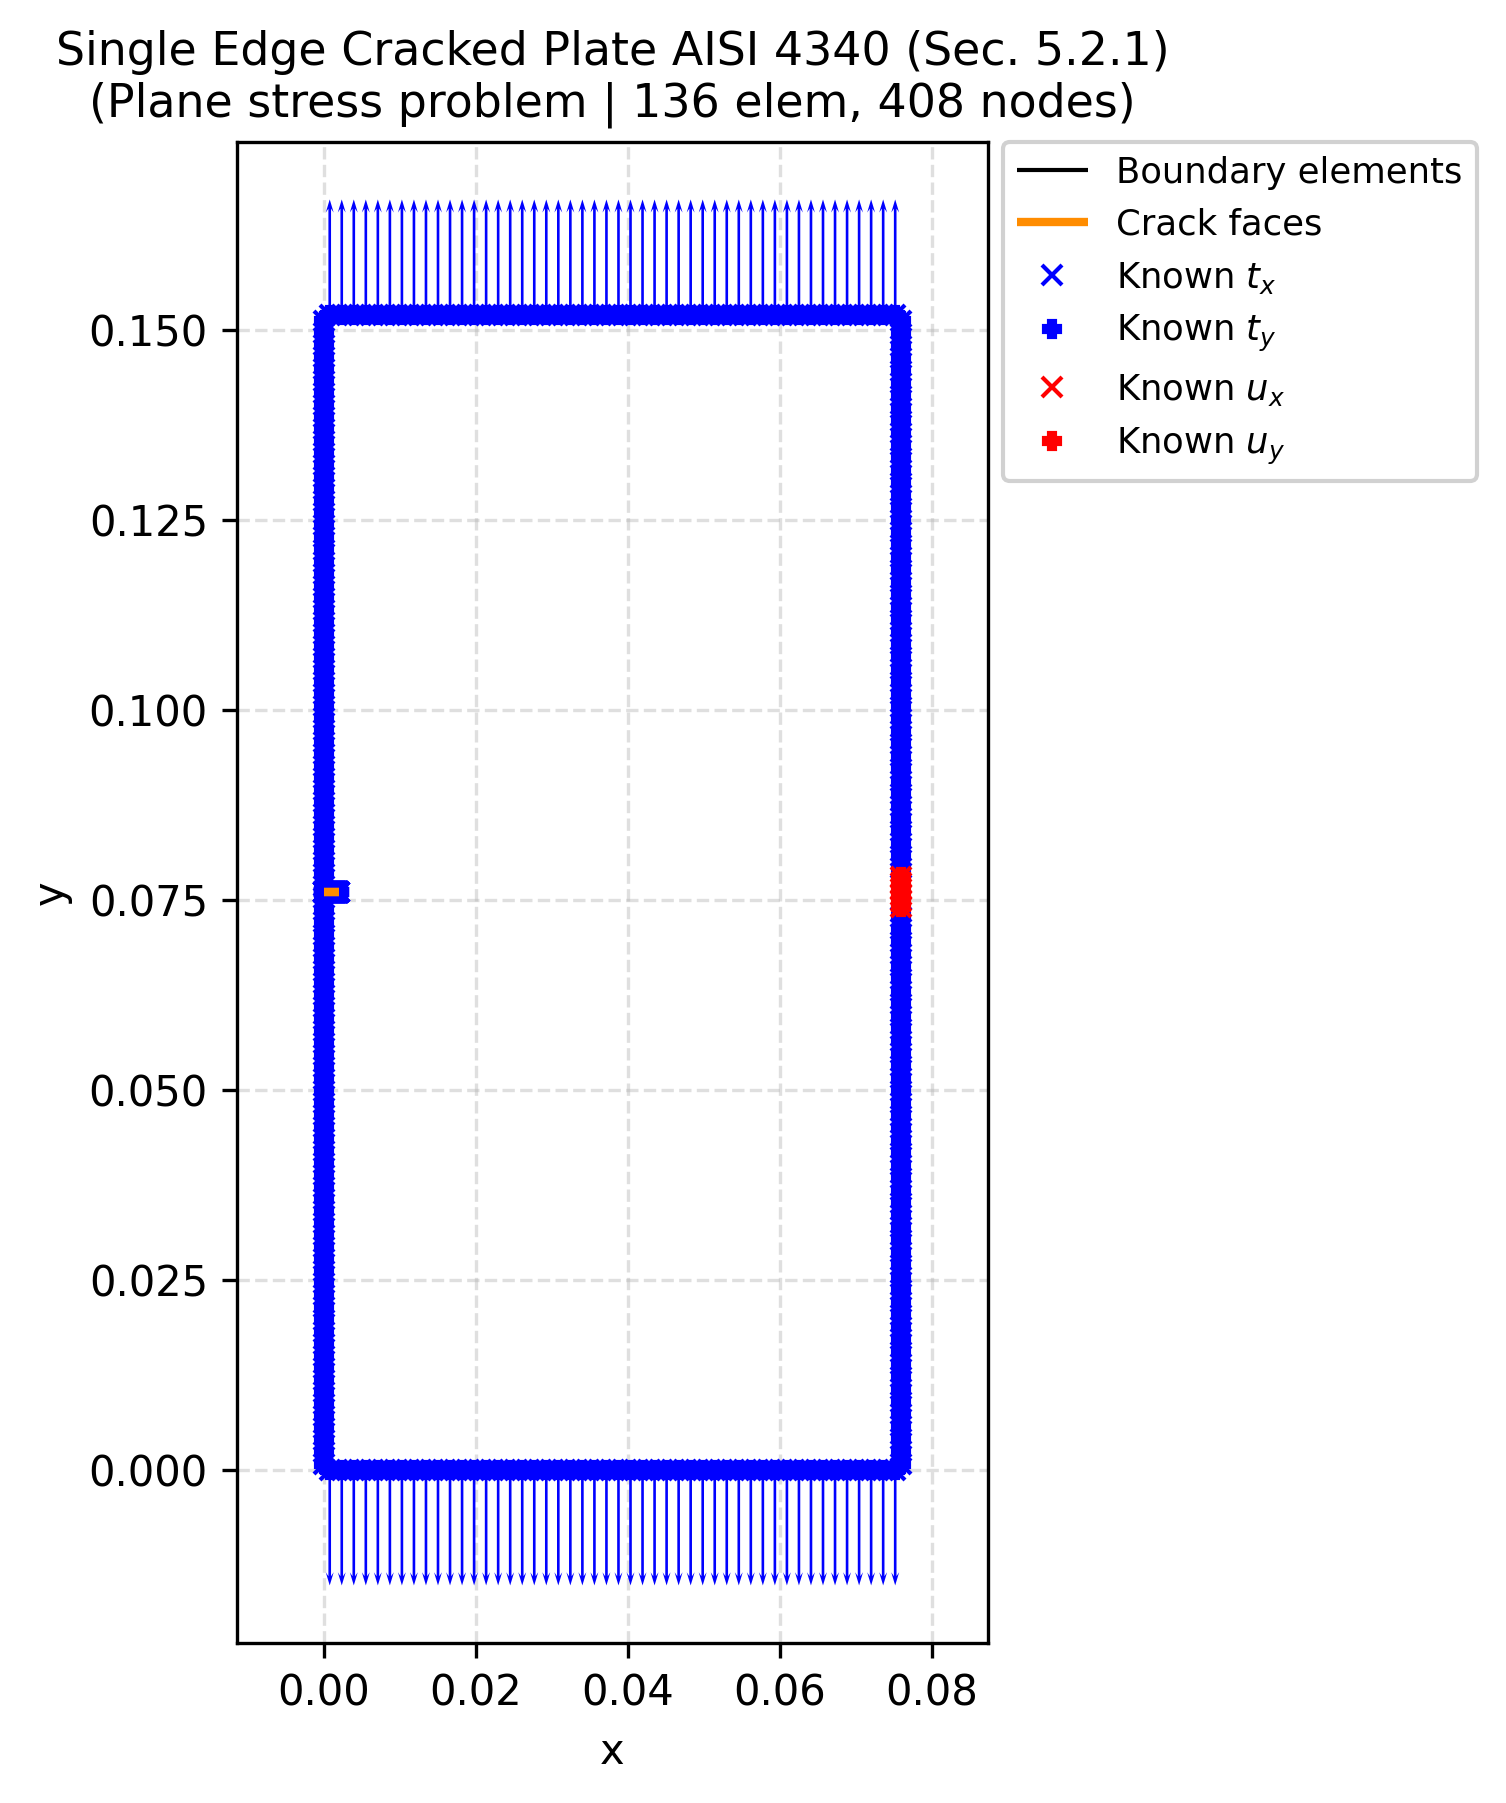

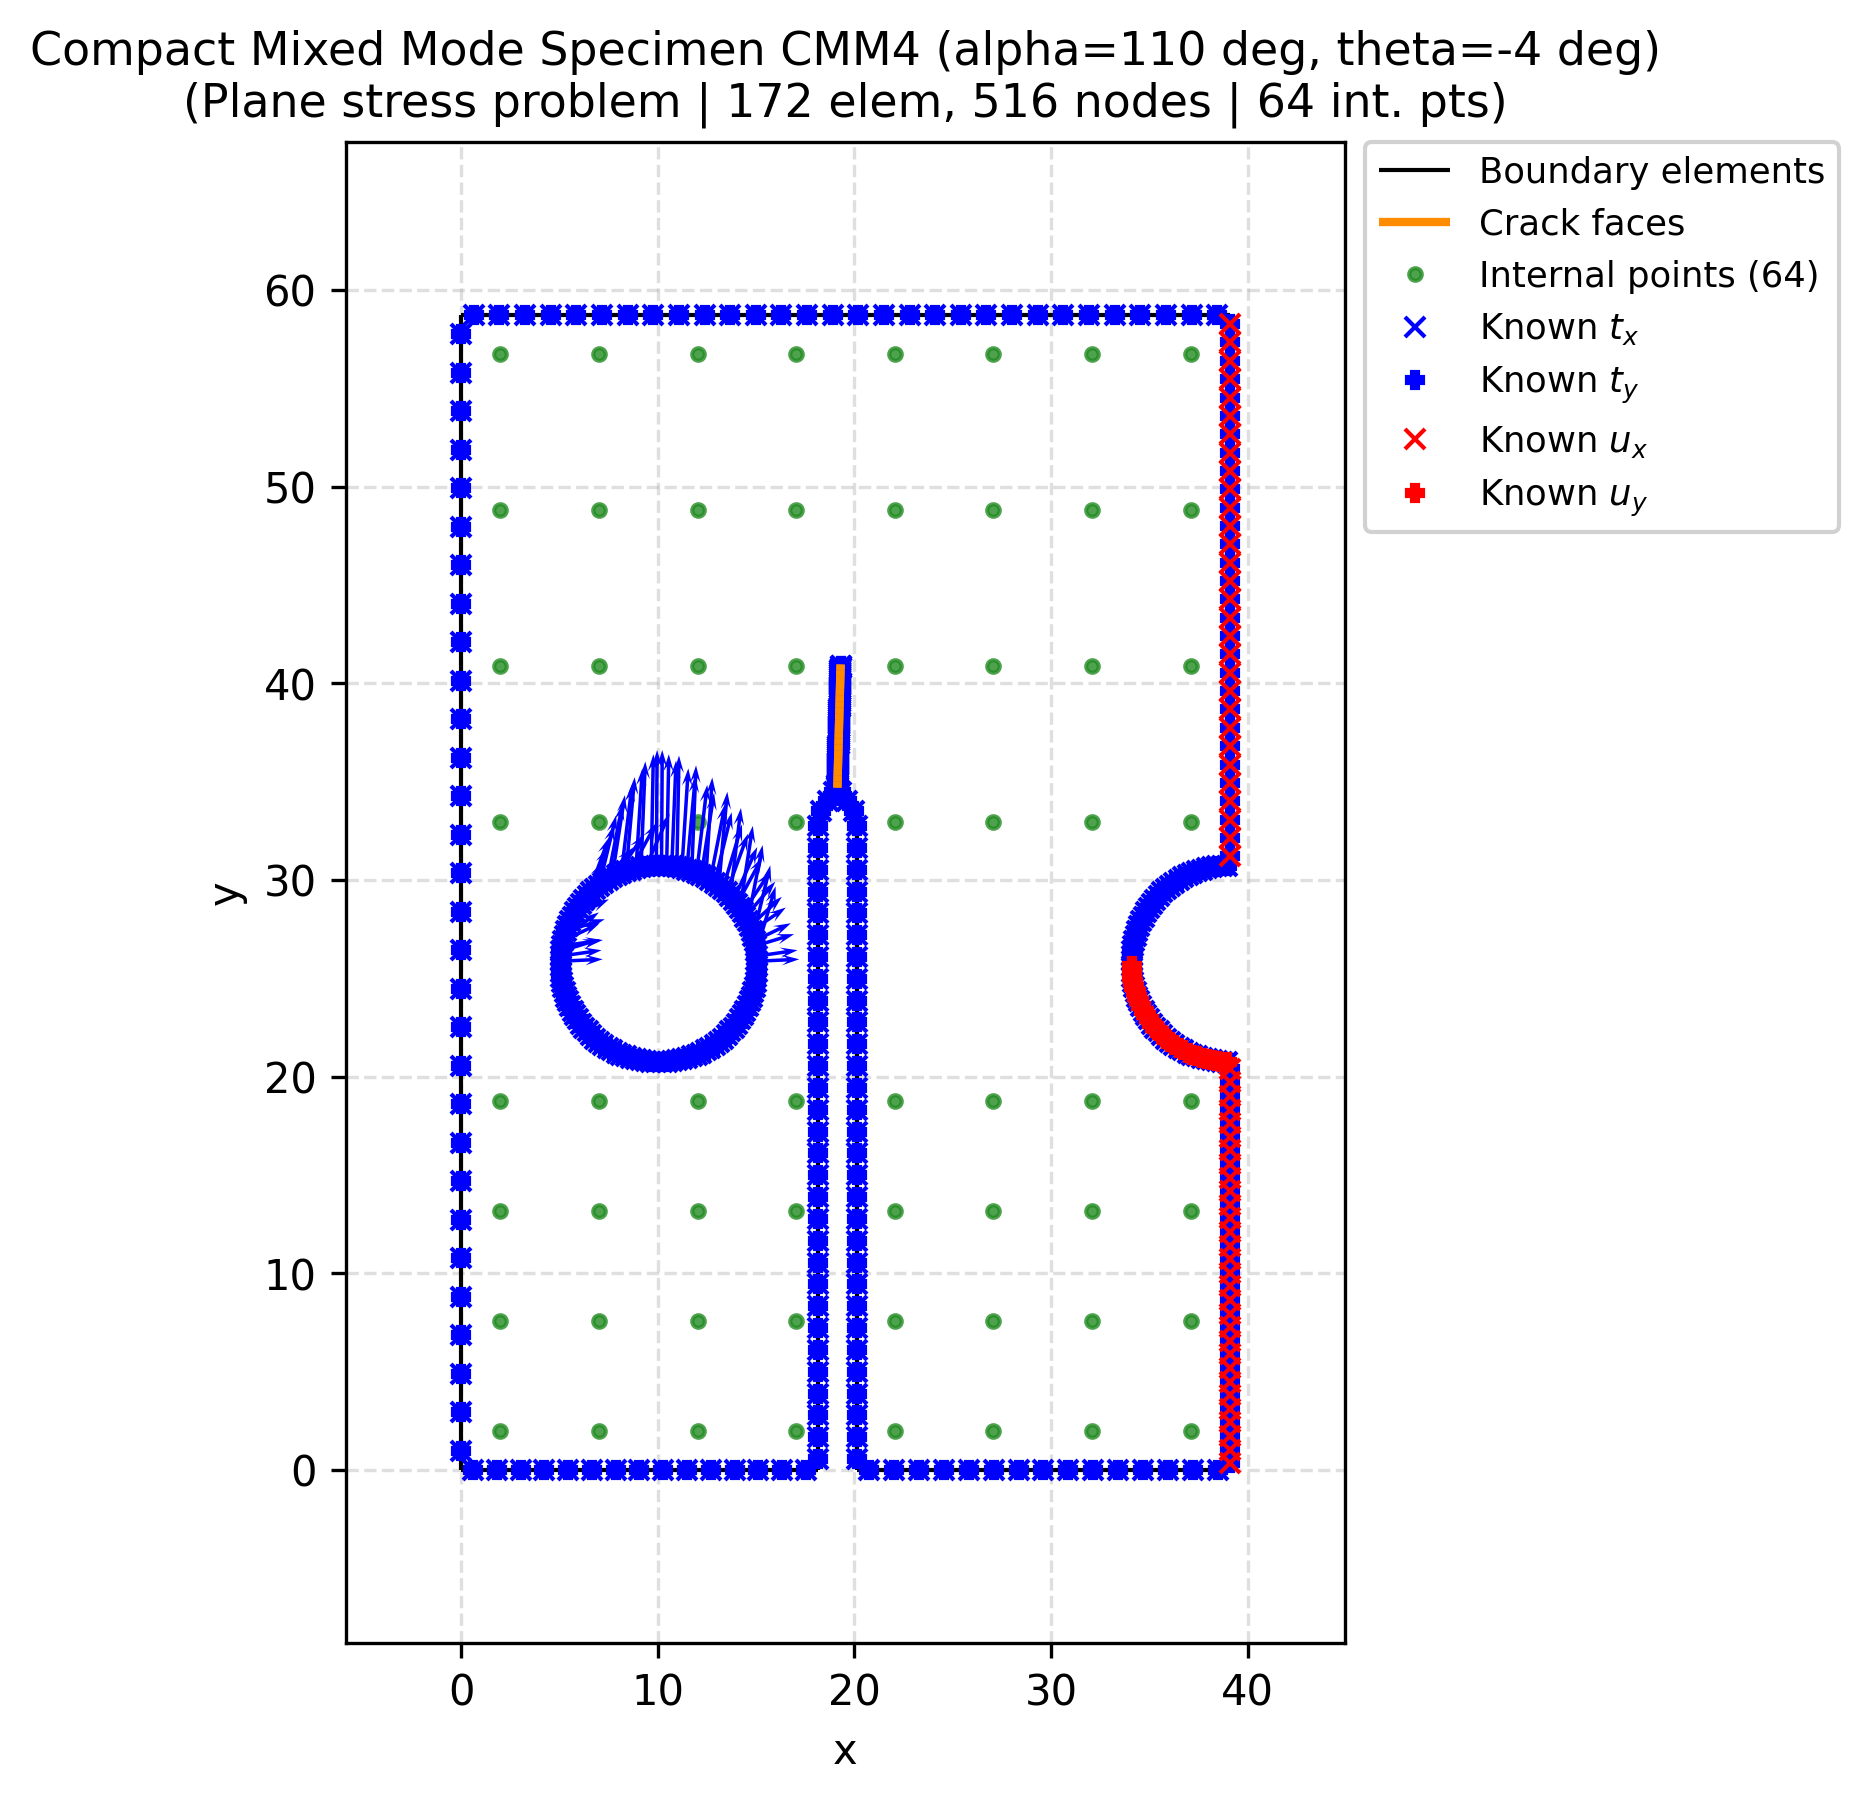

In [5]:
# Executa o pré-processamento para os dois exemplos didáticos
inputs_dir = ROOT_DIR / "inputs"
dat_s521, cfg_s521 = run_preproc("s521_single_edge", output_dir=inputs_dir, plot_png=True)
dat_cmm4, cfg_cmm4 = run_preproc("Chambers_CMM_4", output_dir=inputs_dir, plot_png=True)

print("\nVisualização da malha descontínua e condições de contorno geradas:")
display(Image(filename=str(inputs_dir / "s521_single_edge_mesh_bc.png"), width=520))
display(Image(filename=str(inputs_dir / "Chambers_CMM_4_mesh_bc.png"), width=620))

### Inspecionando o Arquivo `.dat` Gerado para o Solver Fortran

Diferentemente da entrada antiga (que exigia dezenas de códigos de linhas, arcos, polinômios e condições de contorno em pontos particulares), o novo arquivo `.dat` entrega diretamente ao Fortran:
- A tabela de **elementos quadráticos descontínuos** (`id`, extremos geométricos `x1, y1, x2, y2`, incidência dos 3 nós `[n1, n2, n3]` e parâmetros `lamb_1 = lamb_2 = 0.66666667`);
- A tabela de **nós funcionais de colocação** (`id`, coordenadas `x, y`, chave `bie` $\in \{1, 2, 3\}$, direção e valores de condição de contorno);
- A topologia das **trincas** (elementos das pontas `ext_el_num` e pares de nós coincidentes `nodes_num`).

In [6]:
with open(dat_s521, "r", encoding="utf-8") as f:
    dat_lines = [next(f) for _ in range(38)]
print("".join(dat_lines))

# =============================================================================
# Arquivo de Entrada Dual-BEM (Fracture 2D - Elementos Quadraticos Descontinuos)
# Gerado automaticamente por preproc.py a partir do Gmsh (.geo -> .msh) + meshio
# =============================================================================
# 1. Titulo da Analise e Identificador (Analysis ID)
Single Edge Cracked Plate AISI 4340 (Sec. 5.2.1)
s521_single_edge
#
# 2. Propriedades do Material e Parametros Gerais:
#    E (Modulo de Young) | nu (Poisson) | plane_state (1=EPT, 2=EPD) | npow (Gao)
2.07000000e+05  0.30000000  1  3
#
# 3. Dimensoes da Malha Descontinua:
#    be_num (Elementos) | bn_num (Nos de Colocacao) | cr_num (Trincas) | in_num (Pts Internos)
136  408  1  0
#
# =============================================================================
# 4. Elementos de Contorno Quadraticos Descontinuos (3 nos por elemento)
#    elem_id  x1(eta=-1)  y1(eta=-1)  x2(eta=+1)  y2(eta=+1)  lamb_1  lamb_2  inc1  inc

## 5. Compilação do Solver Fortran 90 (`bin/fracture_2d.exe`)

O código Fortran em `src/` foi organizado em **10 módulos didáticos** em ordem clara de dependência:
1. `constants_mod.f90` — Precisão dupla (`dp`), constantes matemáticas e tratamento de erros;
2. `quadrature_mod.f90` — Pontos e pesos de Gauss-Legendre e Gauss-Laguerre (1 a 20 pontos);
3. `model_mod.f90` — Estruturas de dados da malha descontínua, funções de forma 1D e solver linear `DGESV` (LAPACK);
4. `kelvin_sol_mod.f90` — Soluções fundamentais elásticas 2D de Kelvin;
5. `integration_mod.f90` — Integrais regulares, fracamente singulares e Expansão Radial de Gao;
6. `assembler_mod.f90` — Montagem das matrizes Dual-BEM $[H]$ e $[G]$ (paralelizada com OpenMP) e recuperação dos campos;
7. `sif_mod.f90` — Cálculo de $K_I$ e $K_{II}$ (Correlação de Deslocamentos e Integral $J$);
8. `fatigue_prop_mod.f90` — Contagem Rainflow, critério MTC, corretor de Portela e integração de ciclos por Simpson;
9. `io_mod.f90` — Leitura do `.dat` e gravação dos relatórios `.txt` e `.xml`;
10. `main.f90` — Programa principal.

Compilamos o executável utilizando o `Makefile` do projeto:

In [7]:
make_cmd = "mingw32-make" if (os.name == "nt" and shutil.which("mingw32-make")) else "make"
static_flag = ["STATIC=0"] if os.name != "nt" else []

print(f"[*] Compilando o solver Fortran com '{make_cmd}'...")
subprocess.run([make_cmd, "clean", *static_flag], cwd=str(ROOT_DIR), capture_output=True)
res_make = subprocess.run([make_cmd, *static_flag], cwd=str(ROOT_DIR), capture_output=True, text=True)
print(res_make.stdout)

if res_make.returncode == 0:
    print("[OK] Compilação concluída com zero erros e zero avisos!")
else:
    print("[!] Erro na compilação:")
    print(res_make.stderr)

[*] Compilando o solver Fortran com 'mingw32-make'...
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/constants_mod.f90 -o build/constants_mod.o
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/quadrature_mod.f90 -o build/quadrature_mod.o
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/model_mod.f90 -o build/model_mod.o
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/kelvin_sol_mod.f90 -o build/kelvin_sol_mod.o
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/integration_mod.f90 -o build/integration_mod.o
gfortran -O3 -Wall -Wextra -Wno-unused-dummy-argument -Wno-maybe-uninitialized -fopenmp -Jbuild -Ibuild -c src/assembler_mod.f90 -o build/assembler_mod.o
gfortran -O3 -Wall -We

## 6. Execução do Solver Dual-BEM (`bin/fracture_2d.exe`)

Agora executamos o solver para os dois problemas em pastas dedicadas dentro de `results/`:
1. **`s521_single_edge` (Seção 5.2.1)**: Placa de aço AISI 4340 com 1 trinca de borda ($a_0 = 2,00\text{ mm}$), propagando em Modo I até atingir a tenacidade à fratura $K_{IC} = 130\text{ MPa}\sqrt{\text{m}}$ no passo 30 ($a_f = 12,232\text{ mm}$);
2. **`Chambers_CMM_4` (Seção 5.3.2)**: Corpo de prova *Compact Mixed Mode* ($\alpha = 110^\circ, \theta = -4^\circ$), onde o carregamento inicial é dominado por cisalhamento ($K_{II,0} = 401,1\text{ MPa}\sqrt{\text{m}}$ vs $K_{I,0} = 2,36\text{ MPa}\sqrt{\text{m}}$) e a trinca sofre uma deflexão abrupta no primeiro incremento para propagar em Modo I predominante ao longo de 38 passos.

In [8]:
exe_name = "fracture_2d.exe" if (os.name == "nt" and (ROOT_DIR / "bin" / "fracture_2d.exe").exists()) else "fracture_2d"
exe_path = ROOT_DIR / "bin" / exe_name

def run_fracture_solver(case_id: str, dat_path: Path) -> Path:
    """Executa o solver Fortran em results/<case_id> e retorna o diretório de saída."""
    work_dir = ROOT_DIR / "results" / case_id
    work_dir.mkdir(parents=True, exist_ok=True)
    local_dat = work_dir / dat_path.name
    shutil.copy2(dat_path, local_dat)

    t0 = time.perf_counter()
    res = subprocess.run([str(exe_path), str(local_dat)], cwd=str(work_dir), capture_output=True, text=True)
    dt = time.perf_counter() - t0
    print(res.stdout)
    print(f"[OK] Caso '{case_id}' executado em {dt:.2f} s -> {work_dir}\n")
    return work_dir

res_dir_s521 = run_fracture_solver("s521_single_edge", dat_s521)
res_dir_cmm4 = run_fracture_solver("Chambers_CMM_4", dat_cmm4)

******************************************************************************
Fracture 2D - Dual-BEM (Discontinuous Quadratic Elements Edition)
Propagacao Bidimensional de Trincas por Fadiga

 Lendo arquivo de dados pre-processado: C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\results\s521_single_edge\s521_single_edge.dat
 Numero de elementos de contorno (descontinuos) = 136
 Numero de nos funcionais de colocacao          = 408

 Montando o sistema de equacoes Dual-BEM (Passo 0)...
 Resolvendo o sistema linear...
 Avaliando Fatores de Intensidade de Tensao (Passo 0)...
 Propagando trinca(s) por 38 passos...
 Propagacao concluida com sucesso!
******************************************************************************

[OK] Caso 's521_single_edge' executado em 16.36 s -> C:\Users\Adm\OneDrive - unb.br\Antigravity\CrackPropagation2D\results\s521_single_edge

******************************************************************************
Fracture 2D - Dual-BEM (Discontin

## 7. Análise dos Resultados Numéricos e Validação com a Dissertação

O solver gera automaticamente os seguintes arquivos na pasta do caso:
- `<id>_results_crack_001.txt`: histórico de $K_I$, $K_{II}$ e $K_{\text{eq}}$ em cada incremento de propagação;
- `<id>_geometry_crack_001.txt`: coordenadas $(x, y)$ das pontas e comprimento acumulado $a$ da trinca;
- `<id>_fatigue_results_crack_001.txt`: número de ciclos por etapa ($\Delta N$) e acumulado ($N_{\text{total}}$) integrados pela Regra 1/3 de Simpson;
- `<id>_results_step_NNN.txt` e `<id>-STEP-NNN.xml`: deslocamentos, trações e tensões no contorno e nos pontos internos em cada passo.

Vamos inspecionar os resultados de `s521_single_edge` e `Chambers_CMM_4` e compará-los com os valores analíticos, numéricos e experimentais da dissertação:

In [9]:
print("=" * 78)
print(" 1) Resultados de Fratura e Fadiga: s521_single_edge (Seção 5.2.1)")
print("=" * 78)
print((res_dir_s521 / "s521_single_edge_results_crack_001.txt").read_text(encoding="utf-8")[:1200] + "...\n")
print((res_dir_s521 / "s521_single_edge_fatigue_results_crack_001.txt").read_text(encoding="utf-8"))

print("=" * 78)
print(" 2) Resultados de Fratura e Fadiga: Chambers_CMM_4 (Seção 5.3.2)")
print("=" * 78)
cmm4_res_lines = (res_dir_cmm4 / "Chambers_CMM_4_results_crack_001.txt").read_text(encoding="utf-8").splitlines()
print("\n".join(cmm4_res_lines[:15]))
print("...")
print("\n".join(cmm4_res_lines[-6:]))
print()
print((res_dir_cmm4 / "Chambers_CMM_4_fatigue_results_crack_001.txt").read_text(encoding="utf-8"))

 1) Resultados de Fratura e Fadiga: s521_single_edge (Seção 5.2.1)
  Step     Length           K_I_1           K_II_1           Keq_1
    0   0.2000000E-02   0.4728844E+02  -0.1069074E-03   0.4728844E+02
    1   0.2100000E-02   0.4852672E+02   0.2659246E-03   0.4852672E+02
    2   0.2200000E-02   0.4972616E+02  -0.1394773E-03   0.4972616E+02
    3   0.2310000E-02   0.5098954E+02  -0.1175418E-03   0.5098954E+02
    4   0.2420000E-02   0.5224767E+02  -0.1085794E-03   0.5224767E+02
    5   0.2541000E-02   0.5356049E+02   0.9786134E-04   0.5356049E+02
    6   0.2662000E-02   0.5486903E+02  -0.4660654E-03   0.5486903E+02
    7   0.2795100E-02   0.5623850E+02   0.8272366E-03   0.5623850E+02
    8   0.2928200E-02   0.5760737E+02  -0.3467637E-03   0.5760737E+02
    9   0.3074610E-02   0.5904259E+02   0.3175726E-03   0.5904259E+02
   10   0.3221020E-02   0.6048067E+02  -0.6126600E-04   0.6048067E+02
   11   0.3382071E-02   0.6203365E+02  -0.5188136E-04   0.6203365E+02
   12   0.3543122E-02   0.

## 8. Pós-Processamento Gráfico: Reproduzindo as Figuras 5.26 a 5.30 da Dissertação (`plot_results.py`)

Utilizamos o módulo `plot_results.py` para ler os arquivos gerados em `results/Chambers_CMM_4` e produzir todas as figuras clássicas do Capítulo 5 da dissertação:
- **Figura 5.26**: Trajetória de propagação da trinca no sistema global $(X, Y)$ e relativo $(\Delta X, \Delta Y)$;
- **Figura 5.27**: Configuração final da malha de elementos de contorno no Passo 38;
- **Figura 5.28**: Configuração deformada ampliada em 40x com destaque para abertura (COD) e deslizamento (CSD) das faces da trinca;
- **Figura 5.29**: Avanço da trinca $\Delta a$ em função do número de ciclos de fadiga $N$;
- **Figura 5.30**: Taxa de propagação $da/dN \times \Delta K_{\text{eq}}$ em escala log-log e regressão da Lei de Paris;
- **Evolução dos FITs**: queda imediata de $K_{II}$ após a deflexão inicial e crescimento de $K_I$.


=== Figura 5.26 — Trajetória de Propagação da Trinca (CMM4) ===

=== Figura 5.27 — Configuração Final da Malha no Passo 38 (CMM4) ===

=== Figura 5.28 — Configuração Deformada Ampliada 40x (CMM4) ===

=== Figura 5.29 — Avanço da Trinca vs Número de Ciclos (CMM4) ===

=== Figura 5.30 — Taxa de Propagação da/dN vs Delta K (CMM4) ===

=== Evolução de K_I, K_II e K_eq ao Longo da Propagação (CMM4) ===

=== Painel Resumo Integrado 2x2 (CMM4) ===


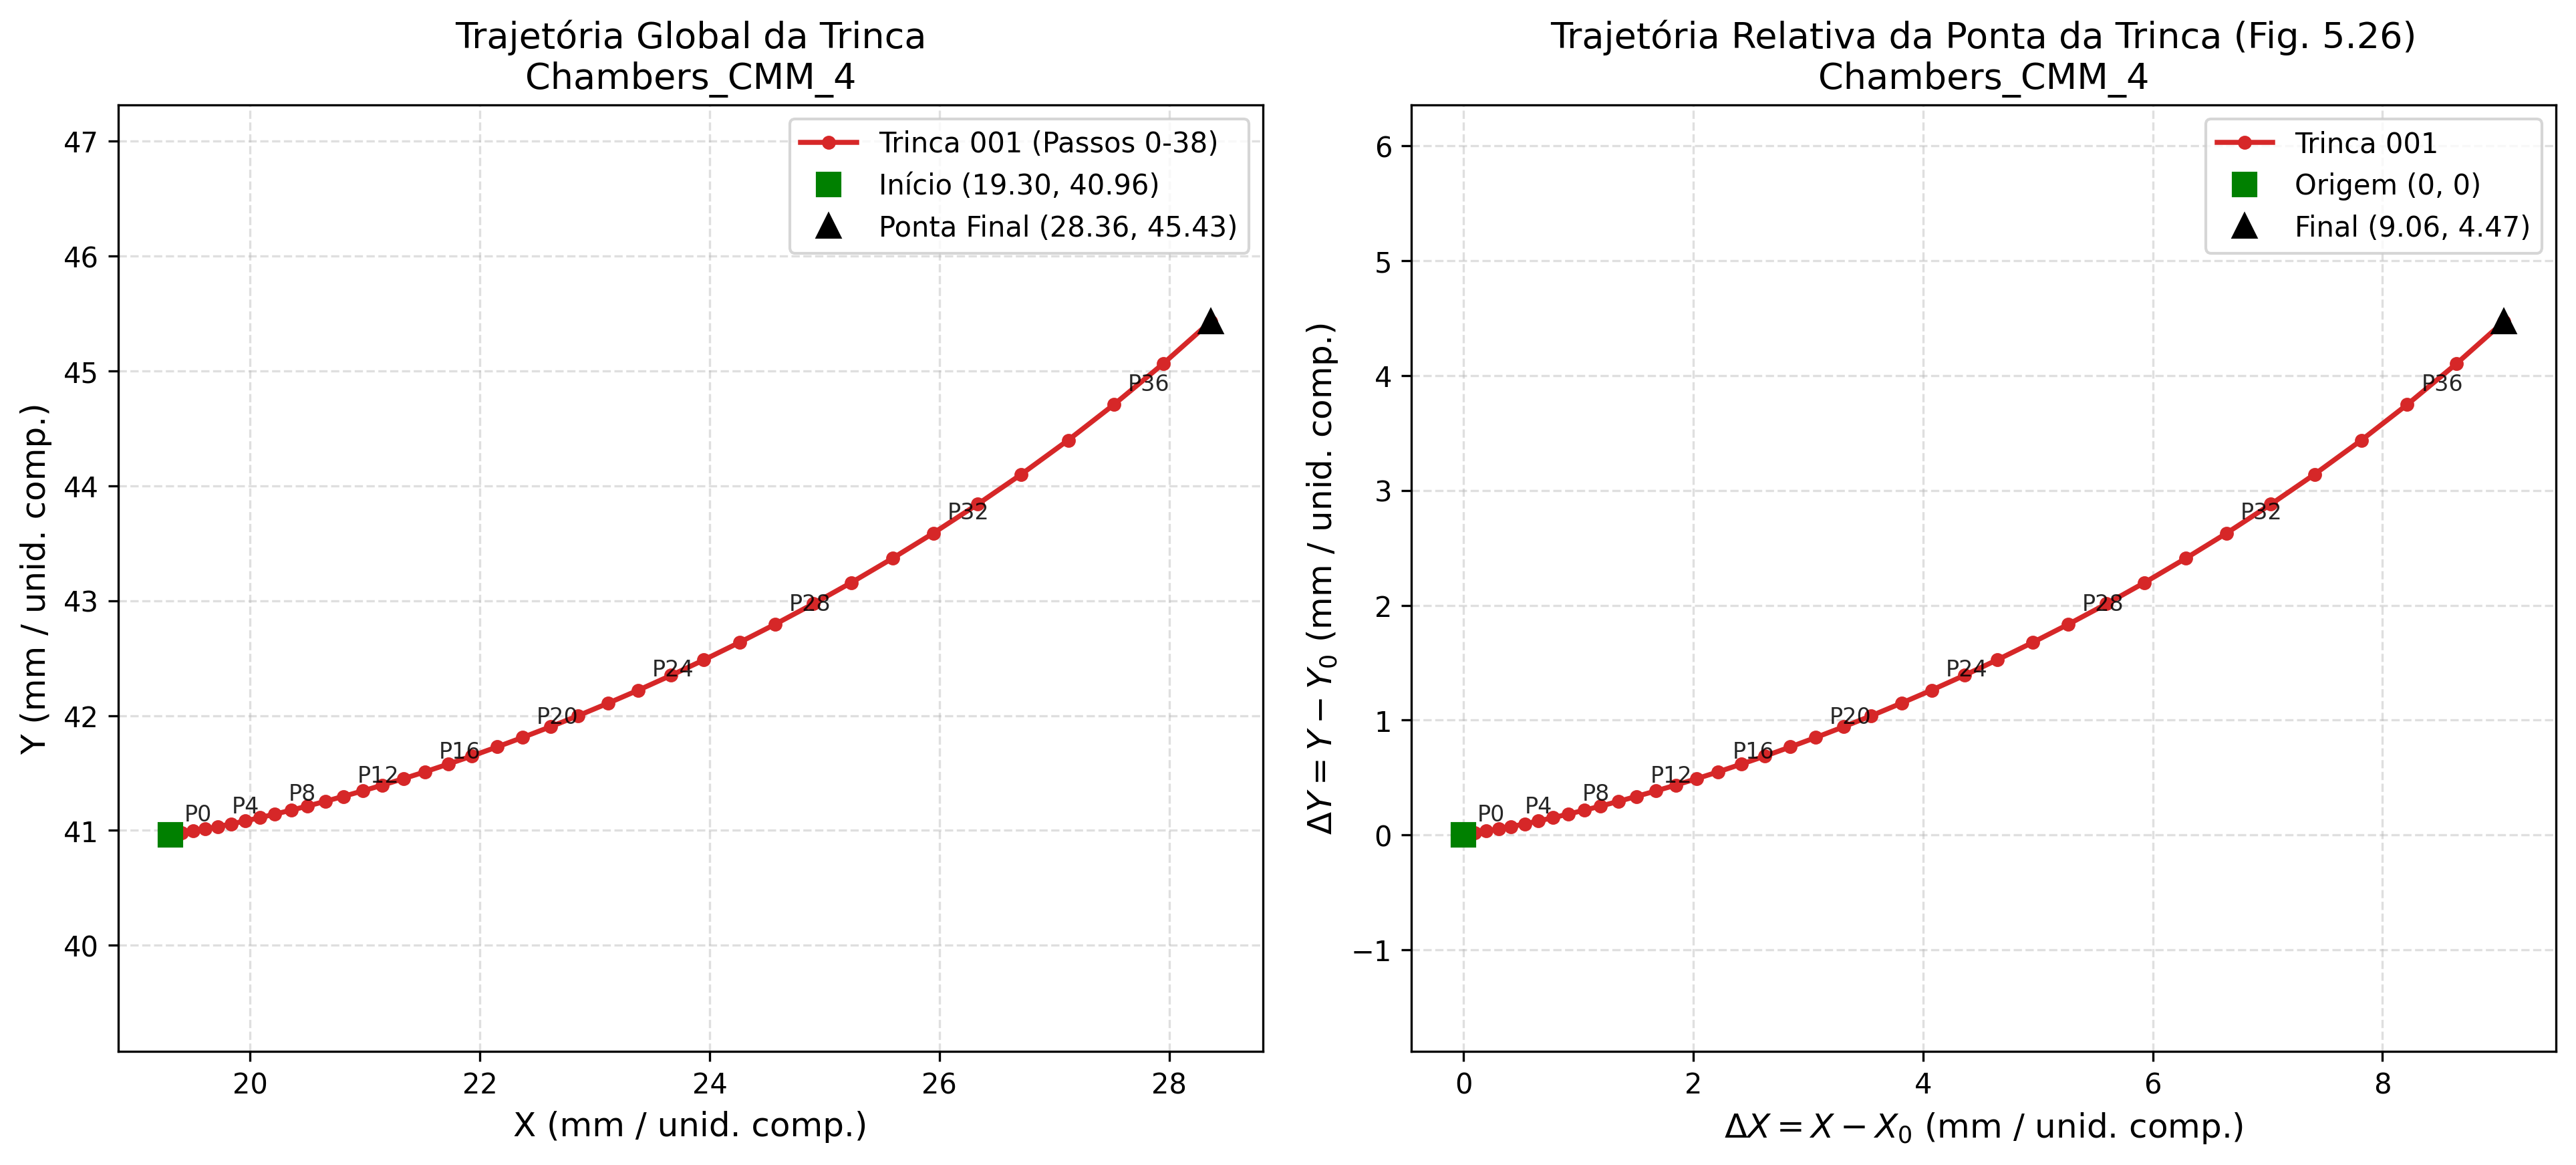

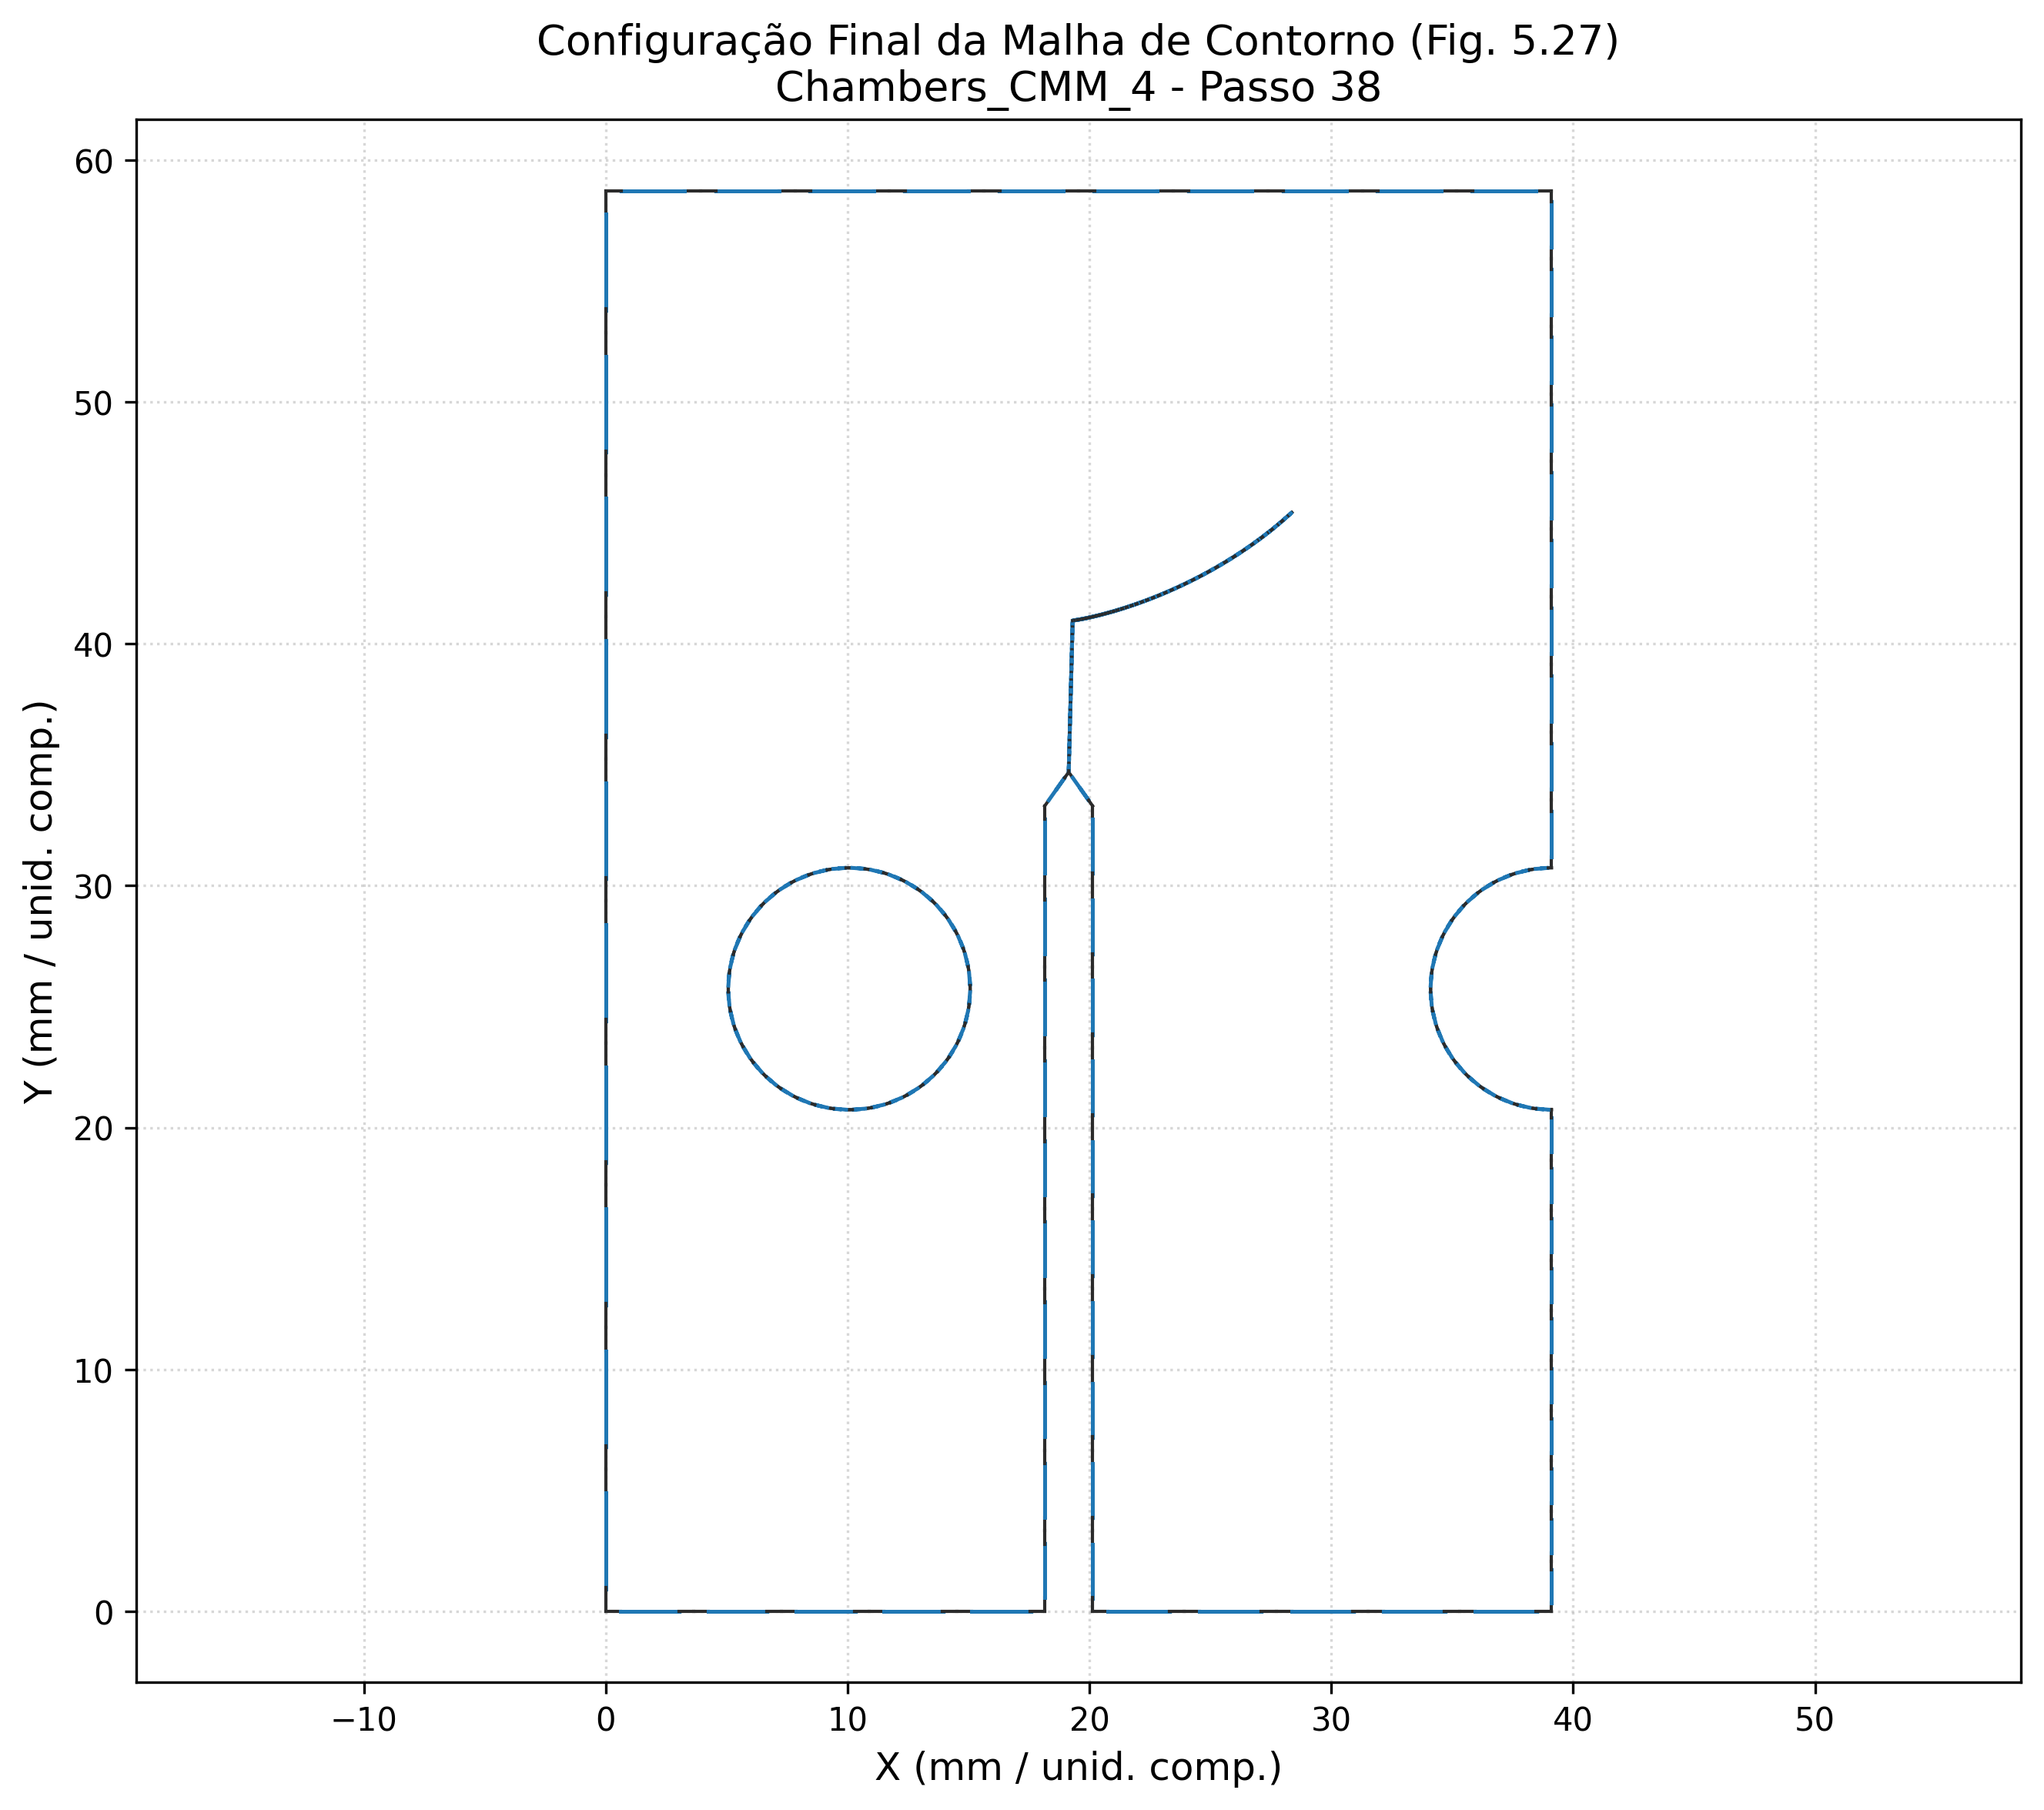

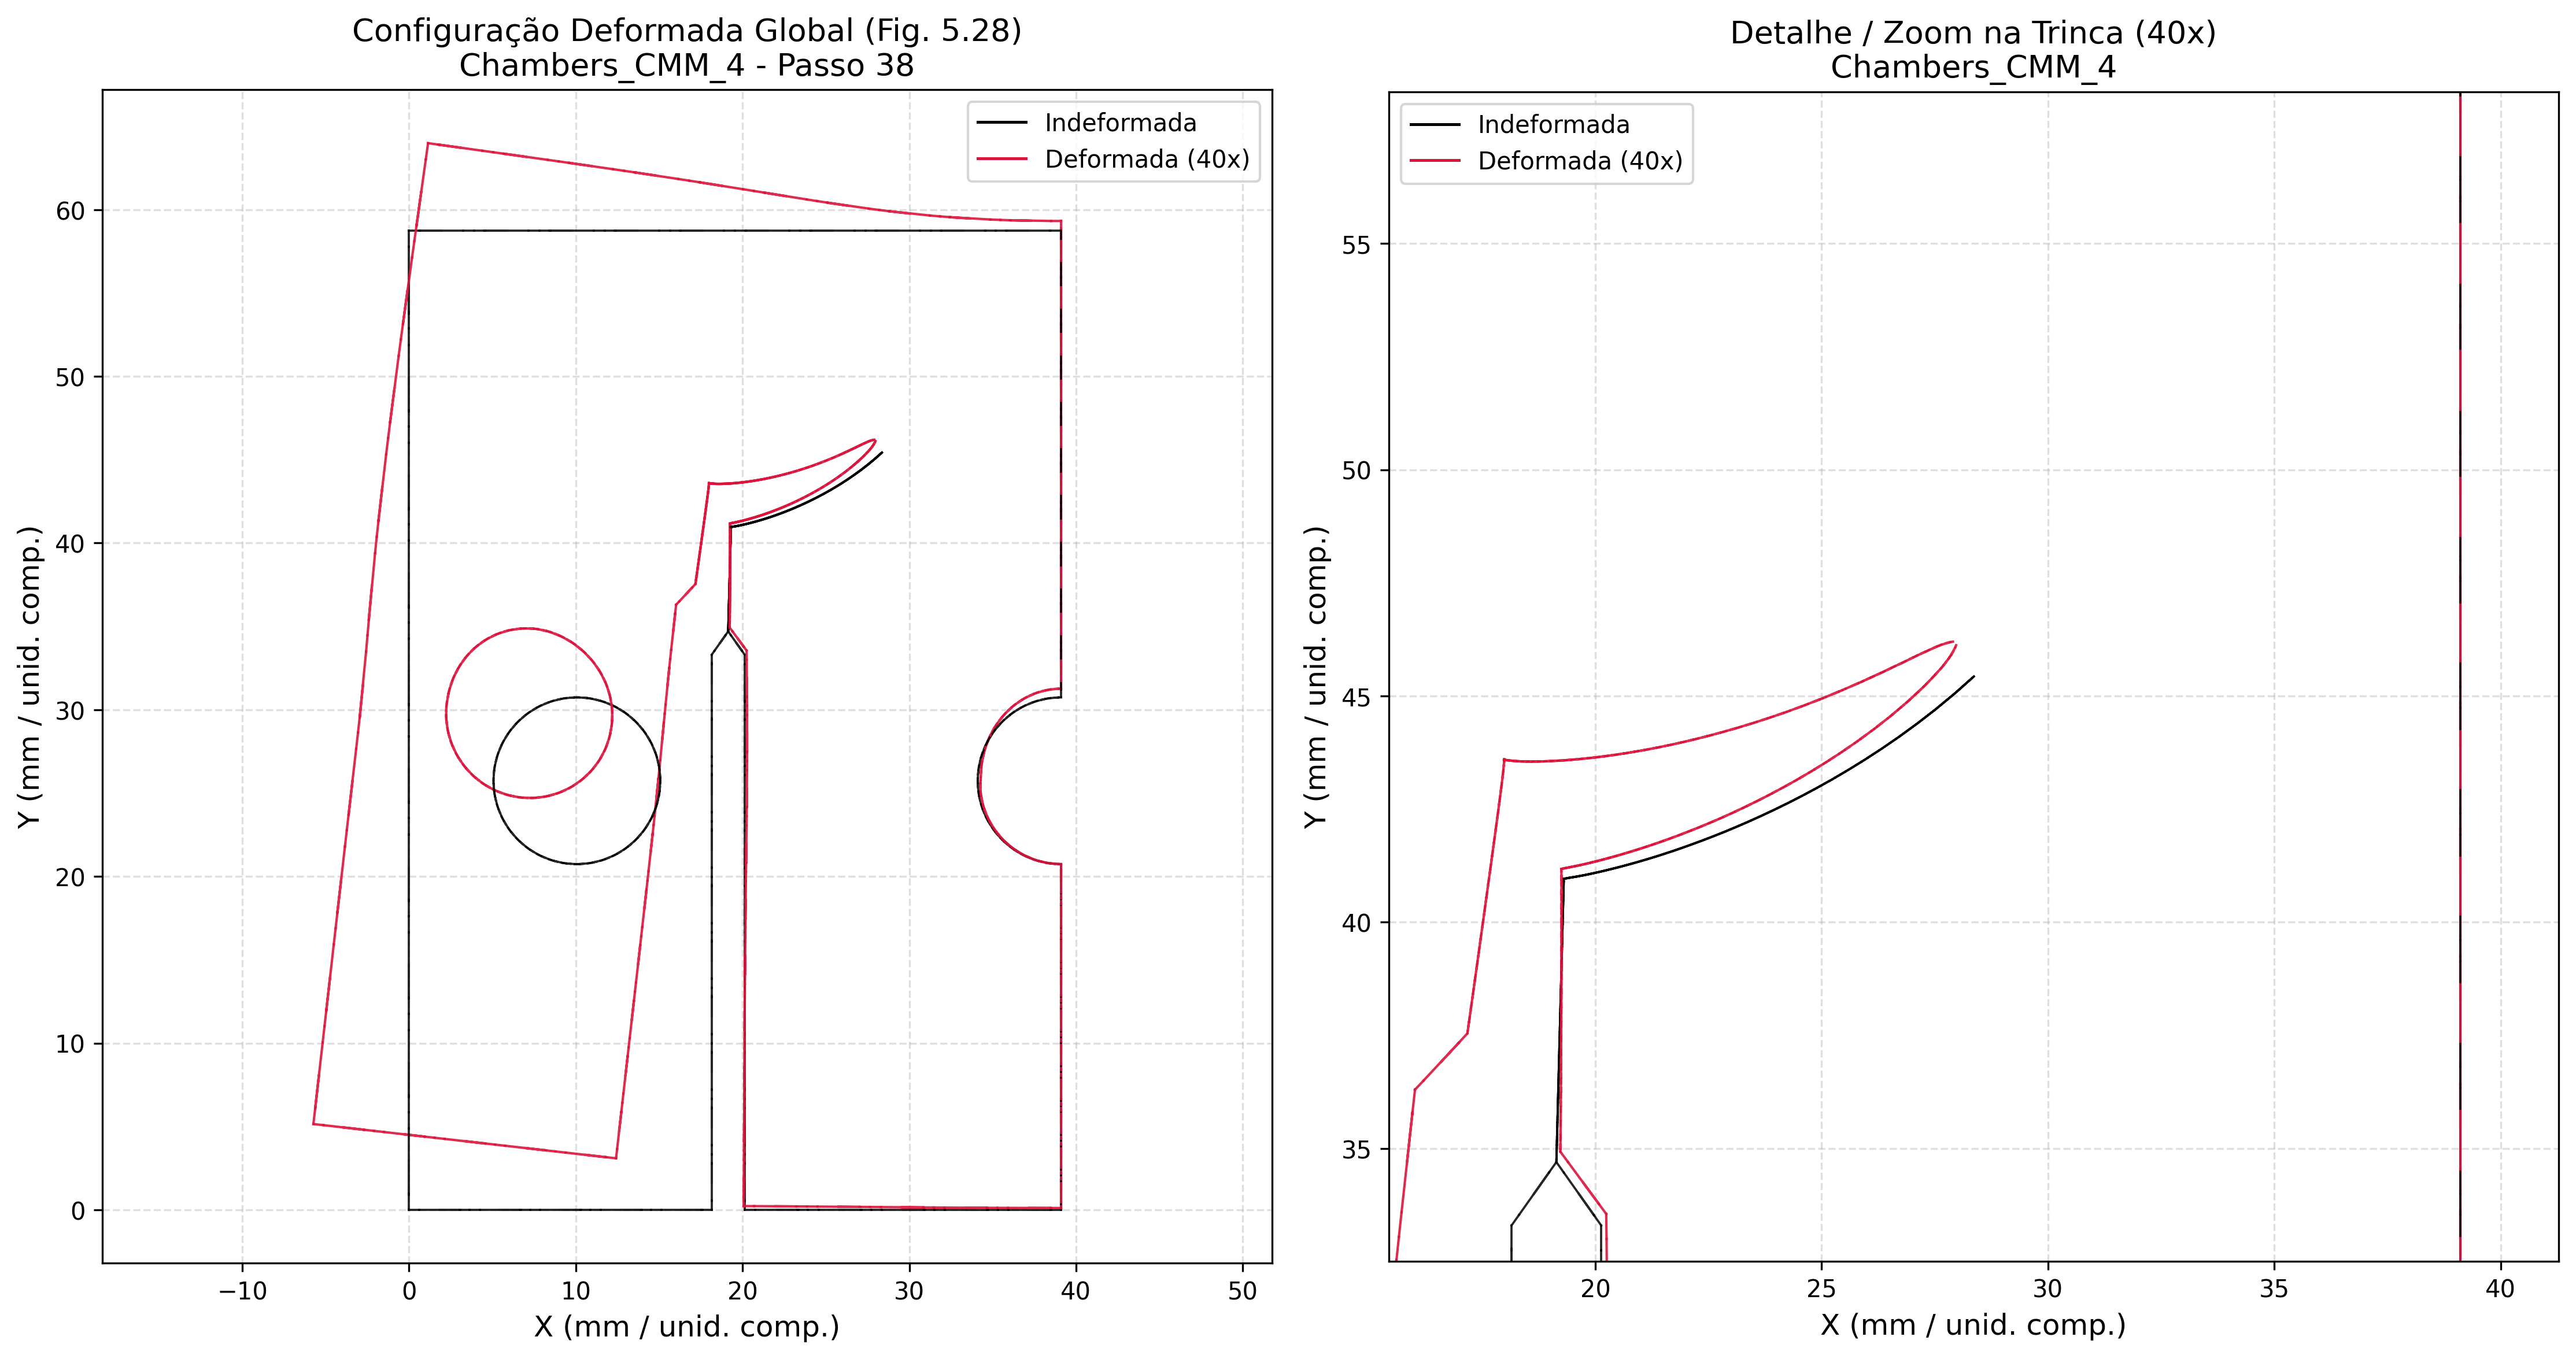

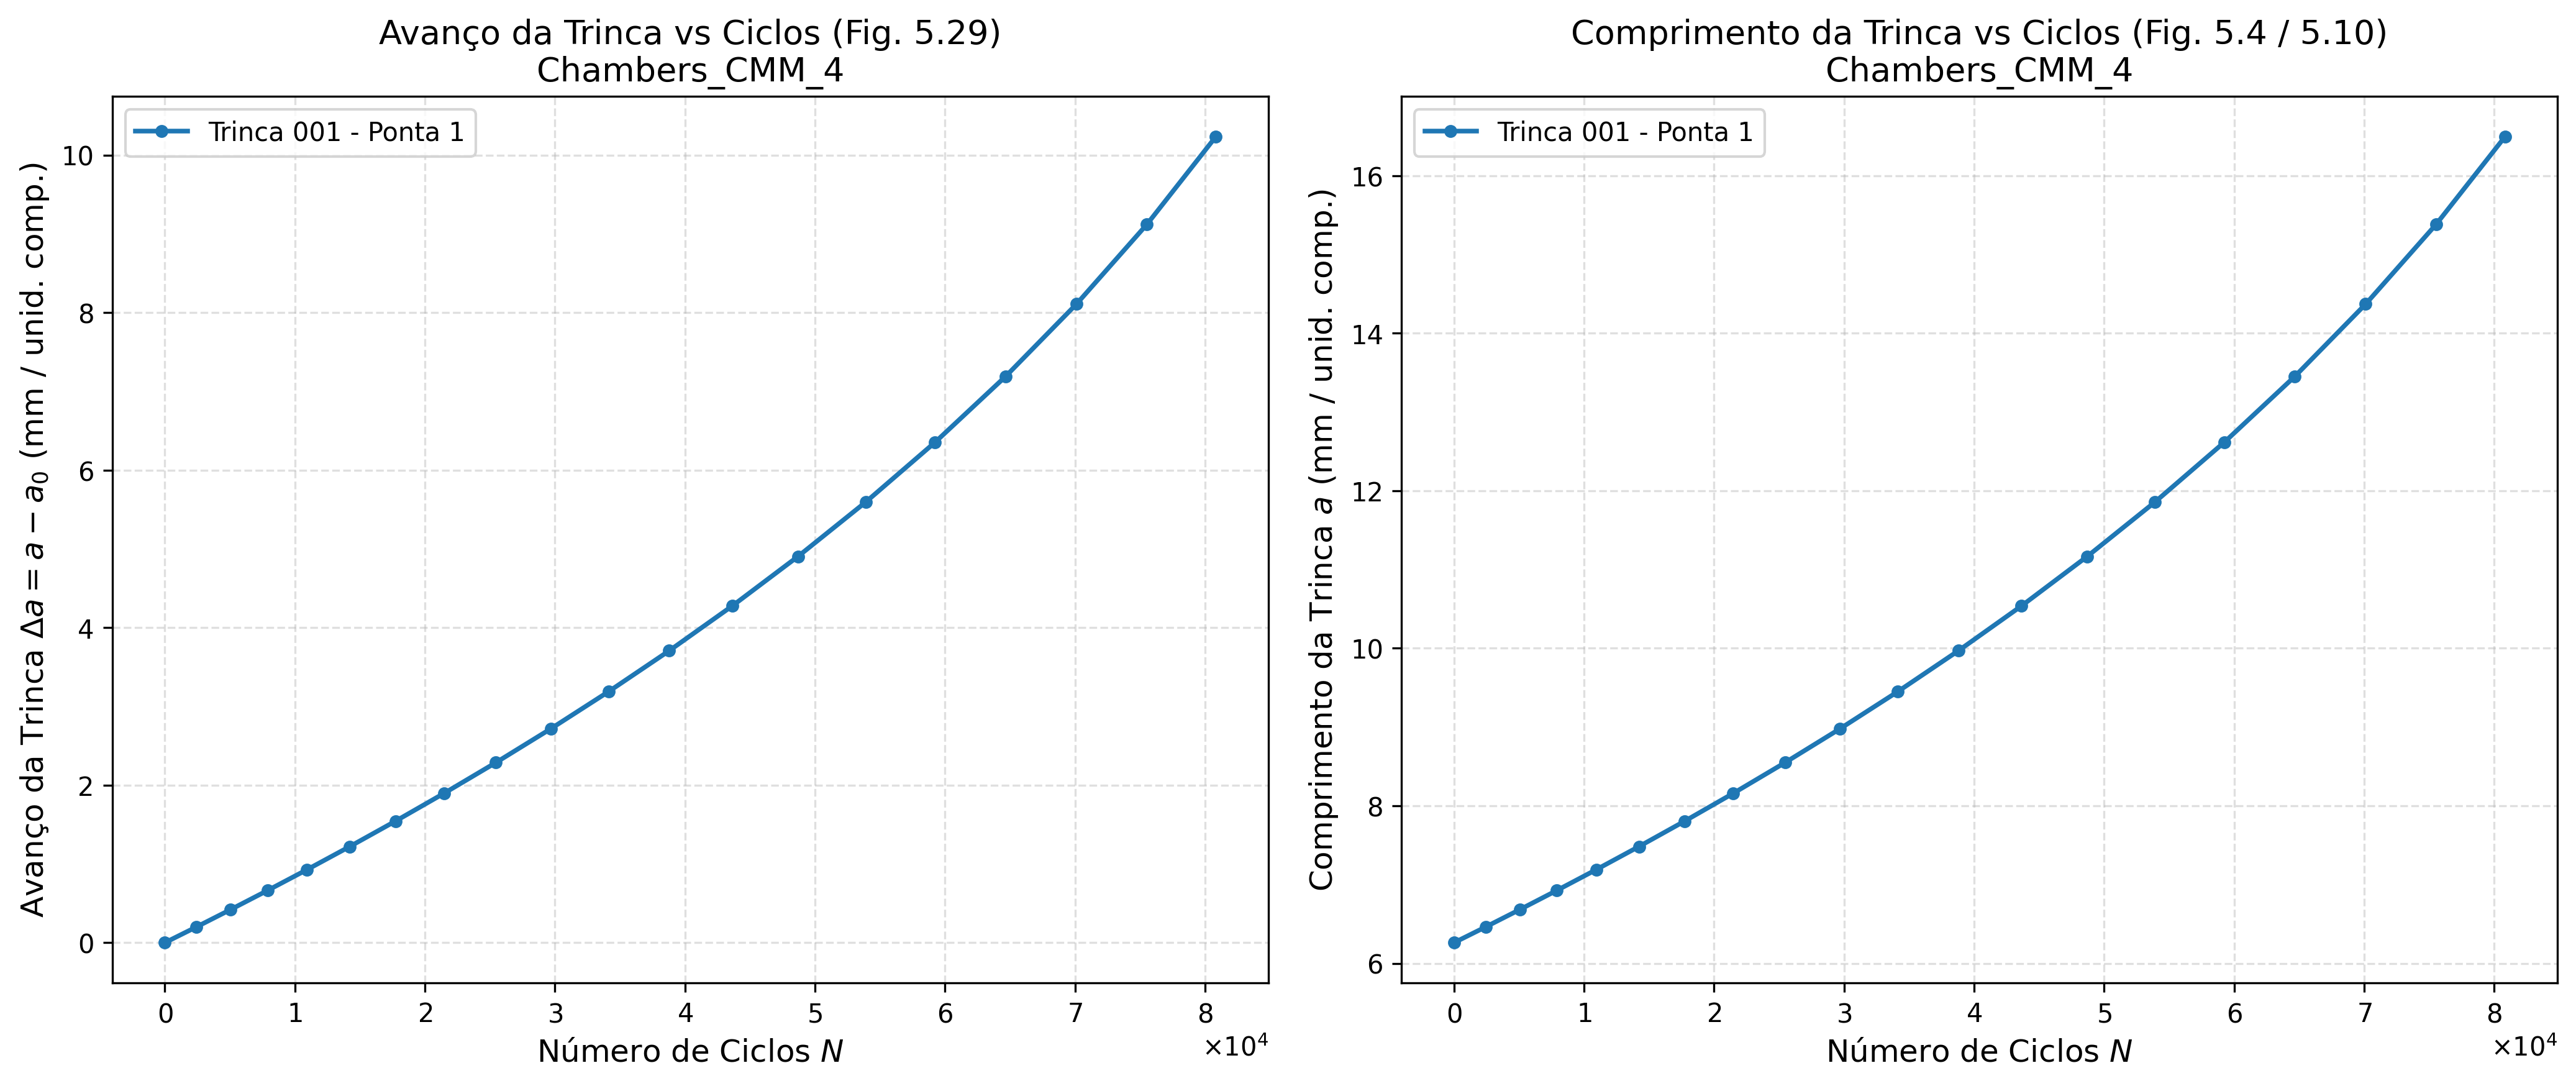

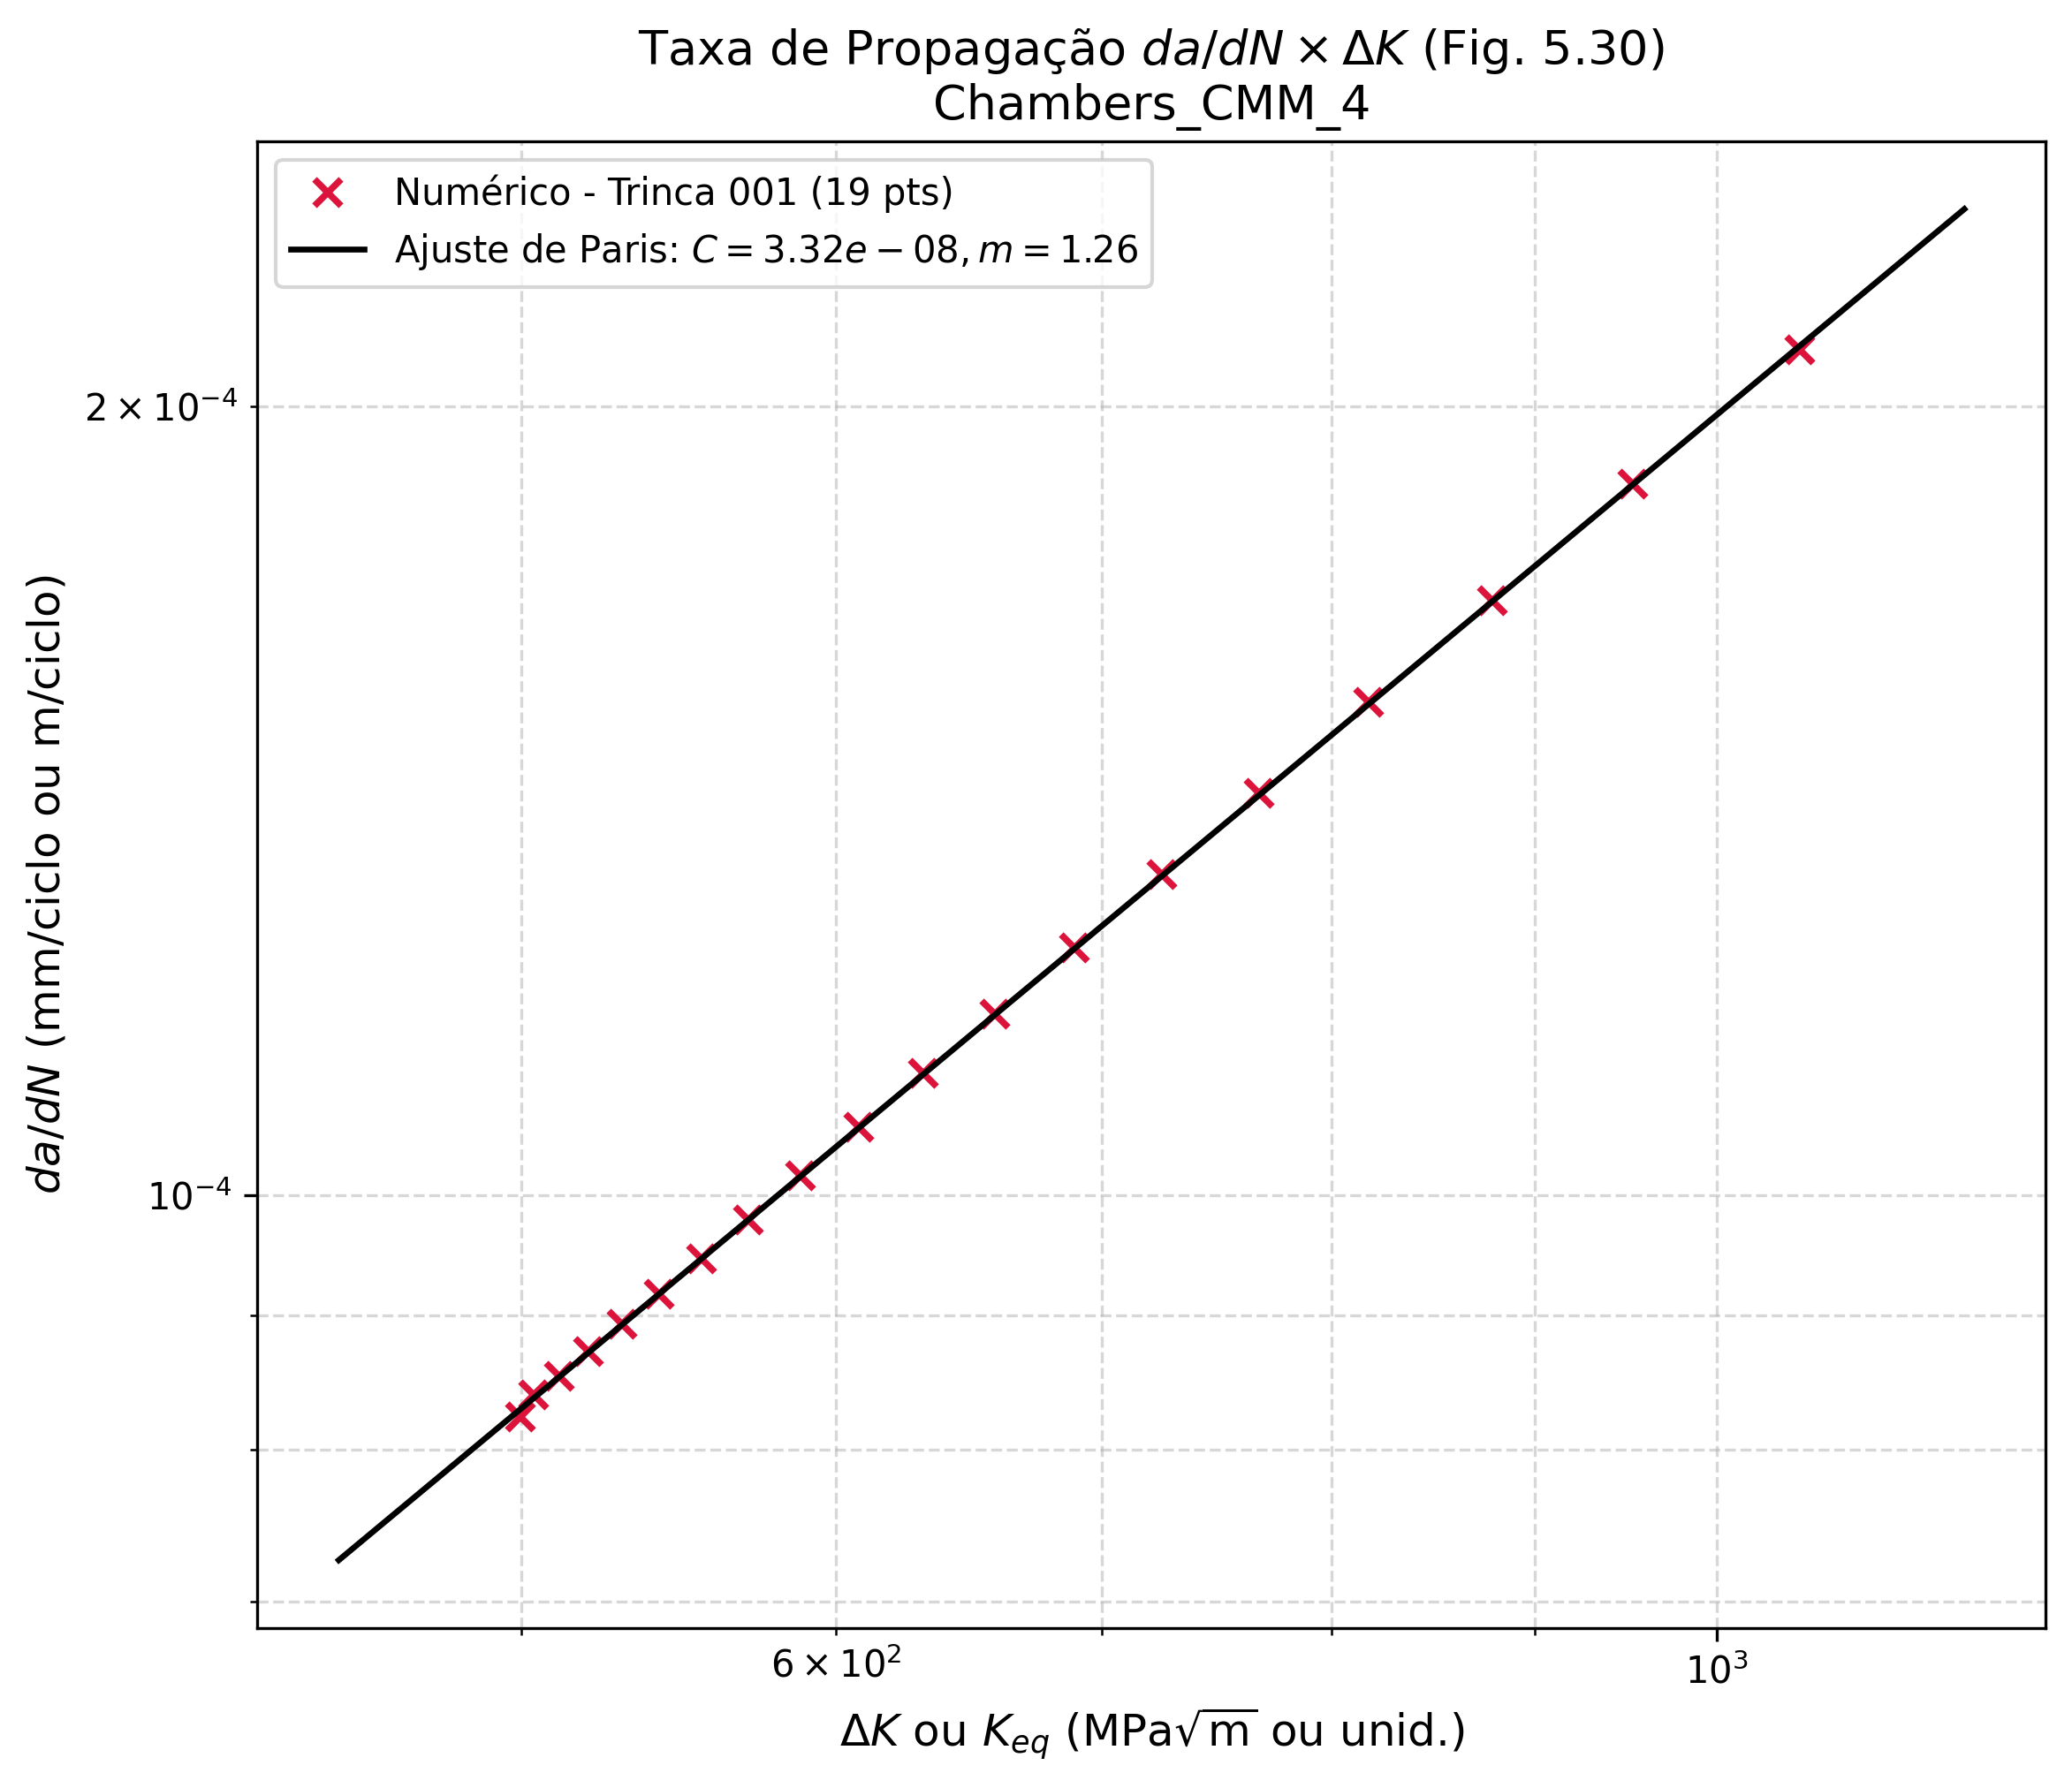

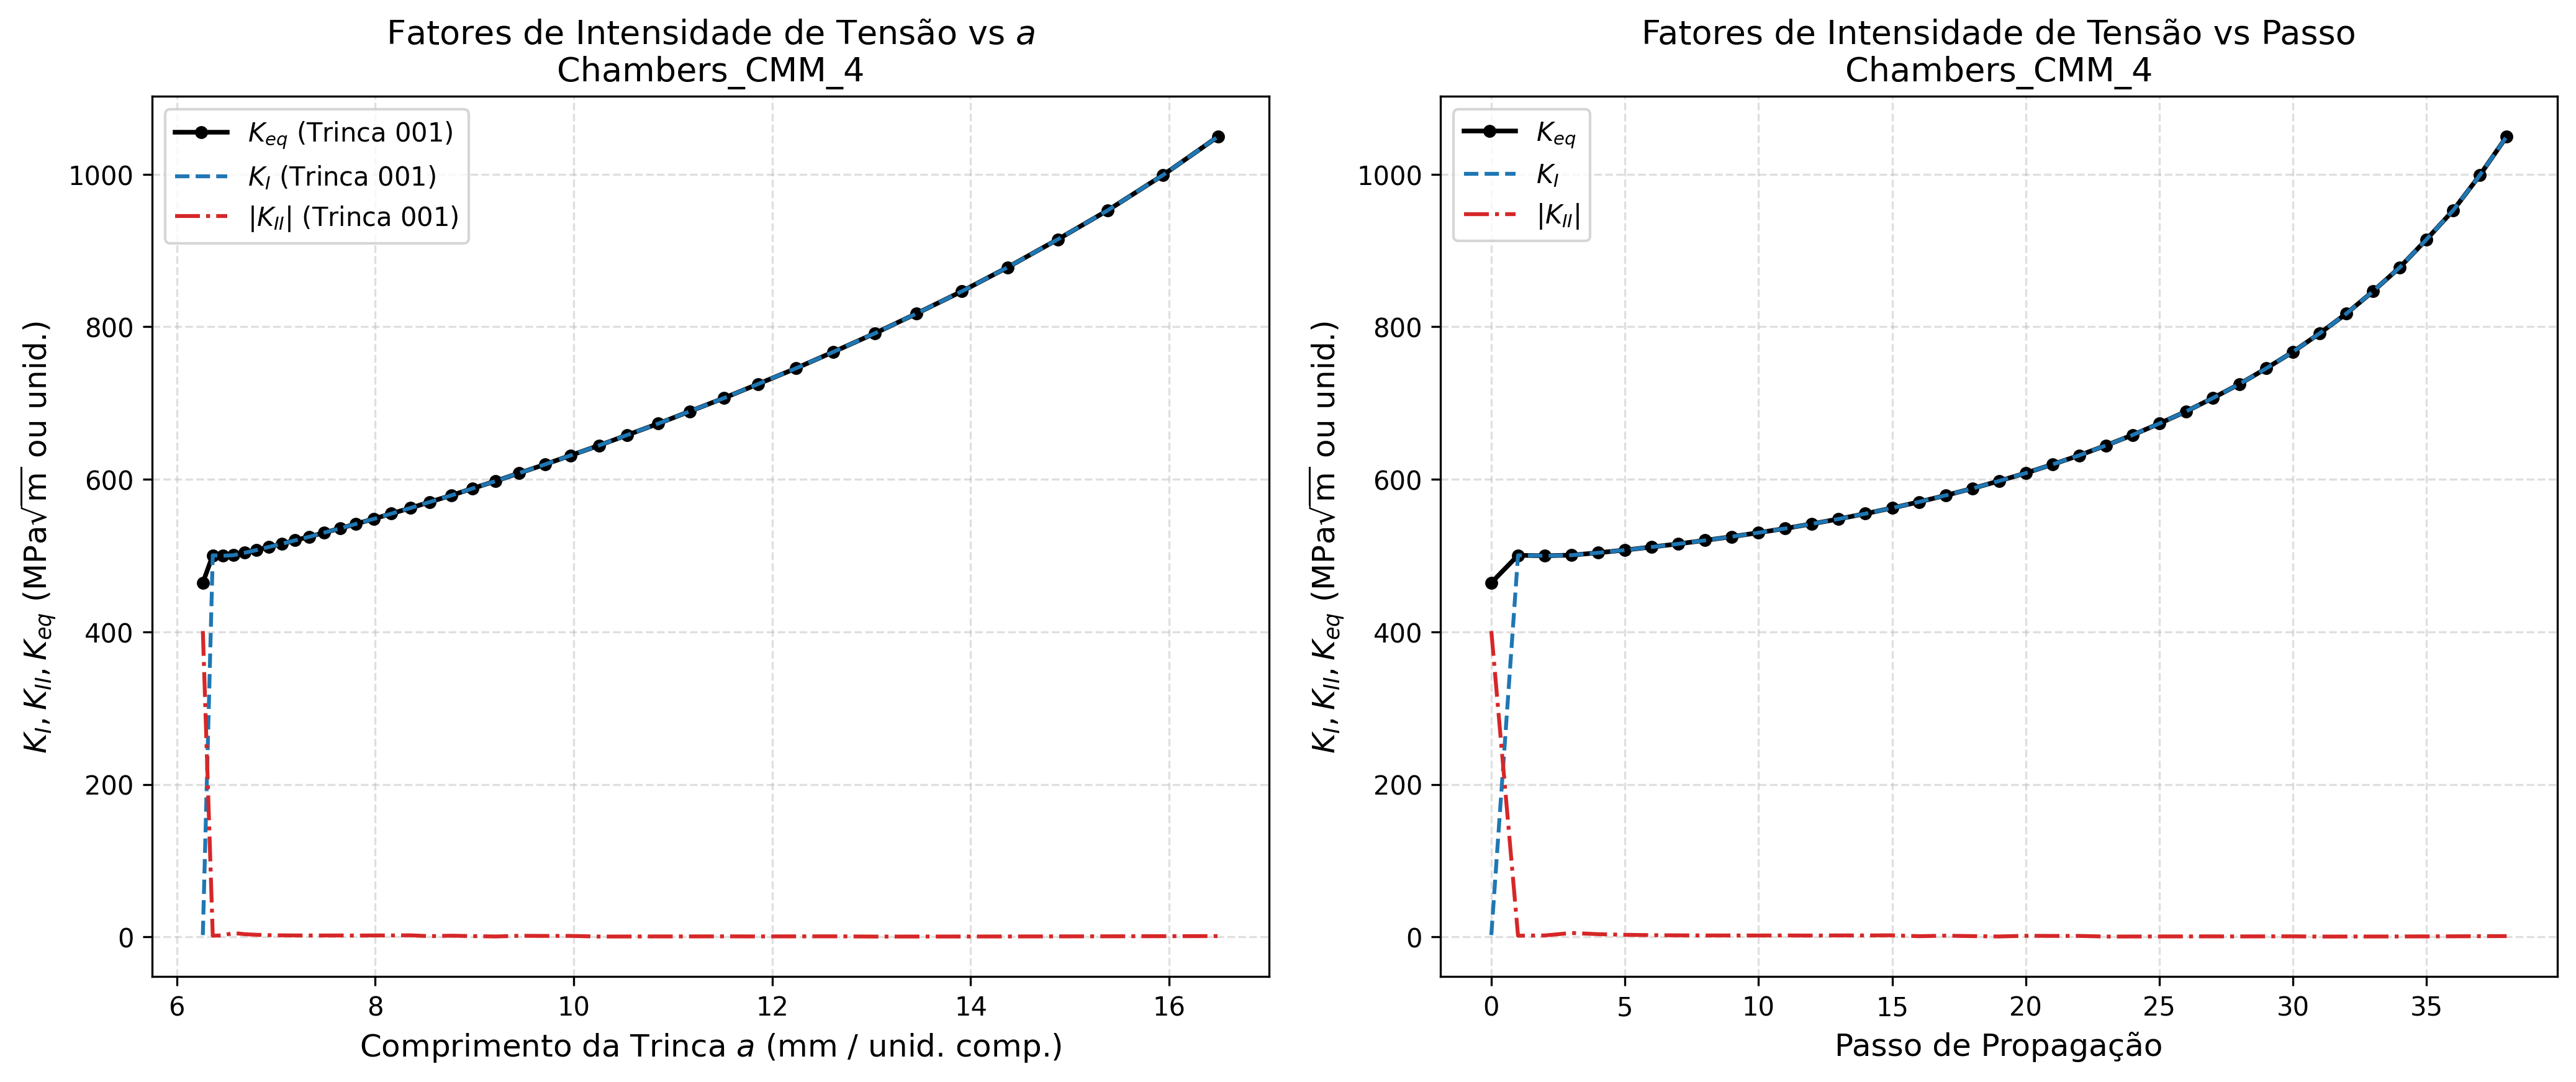

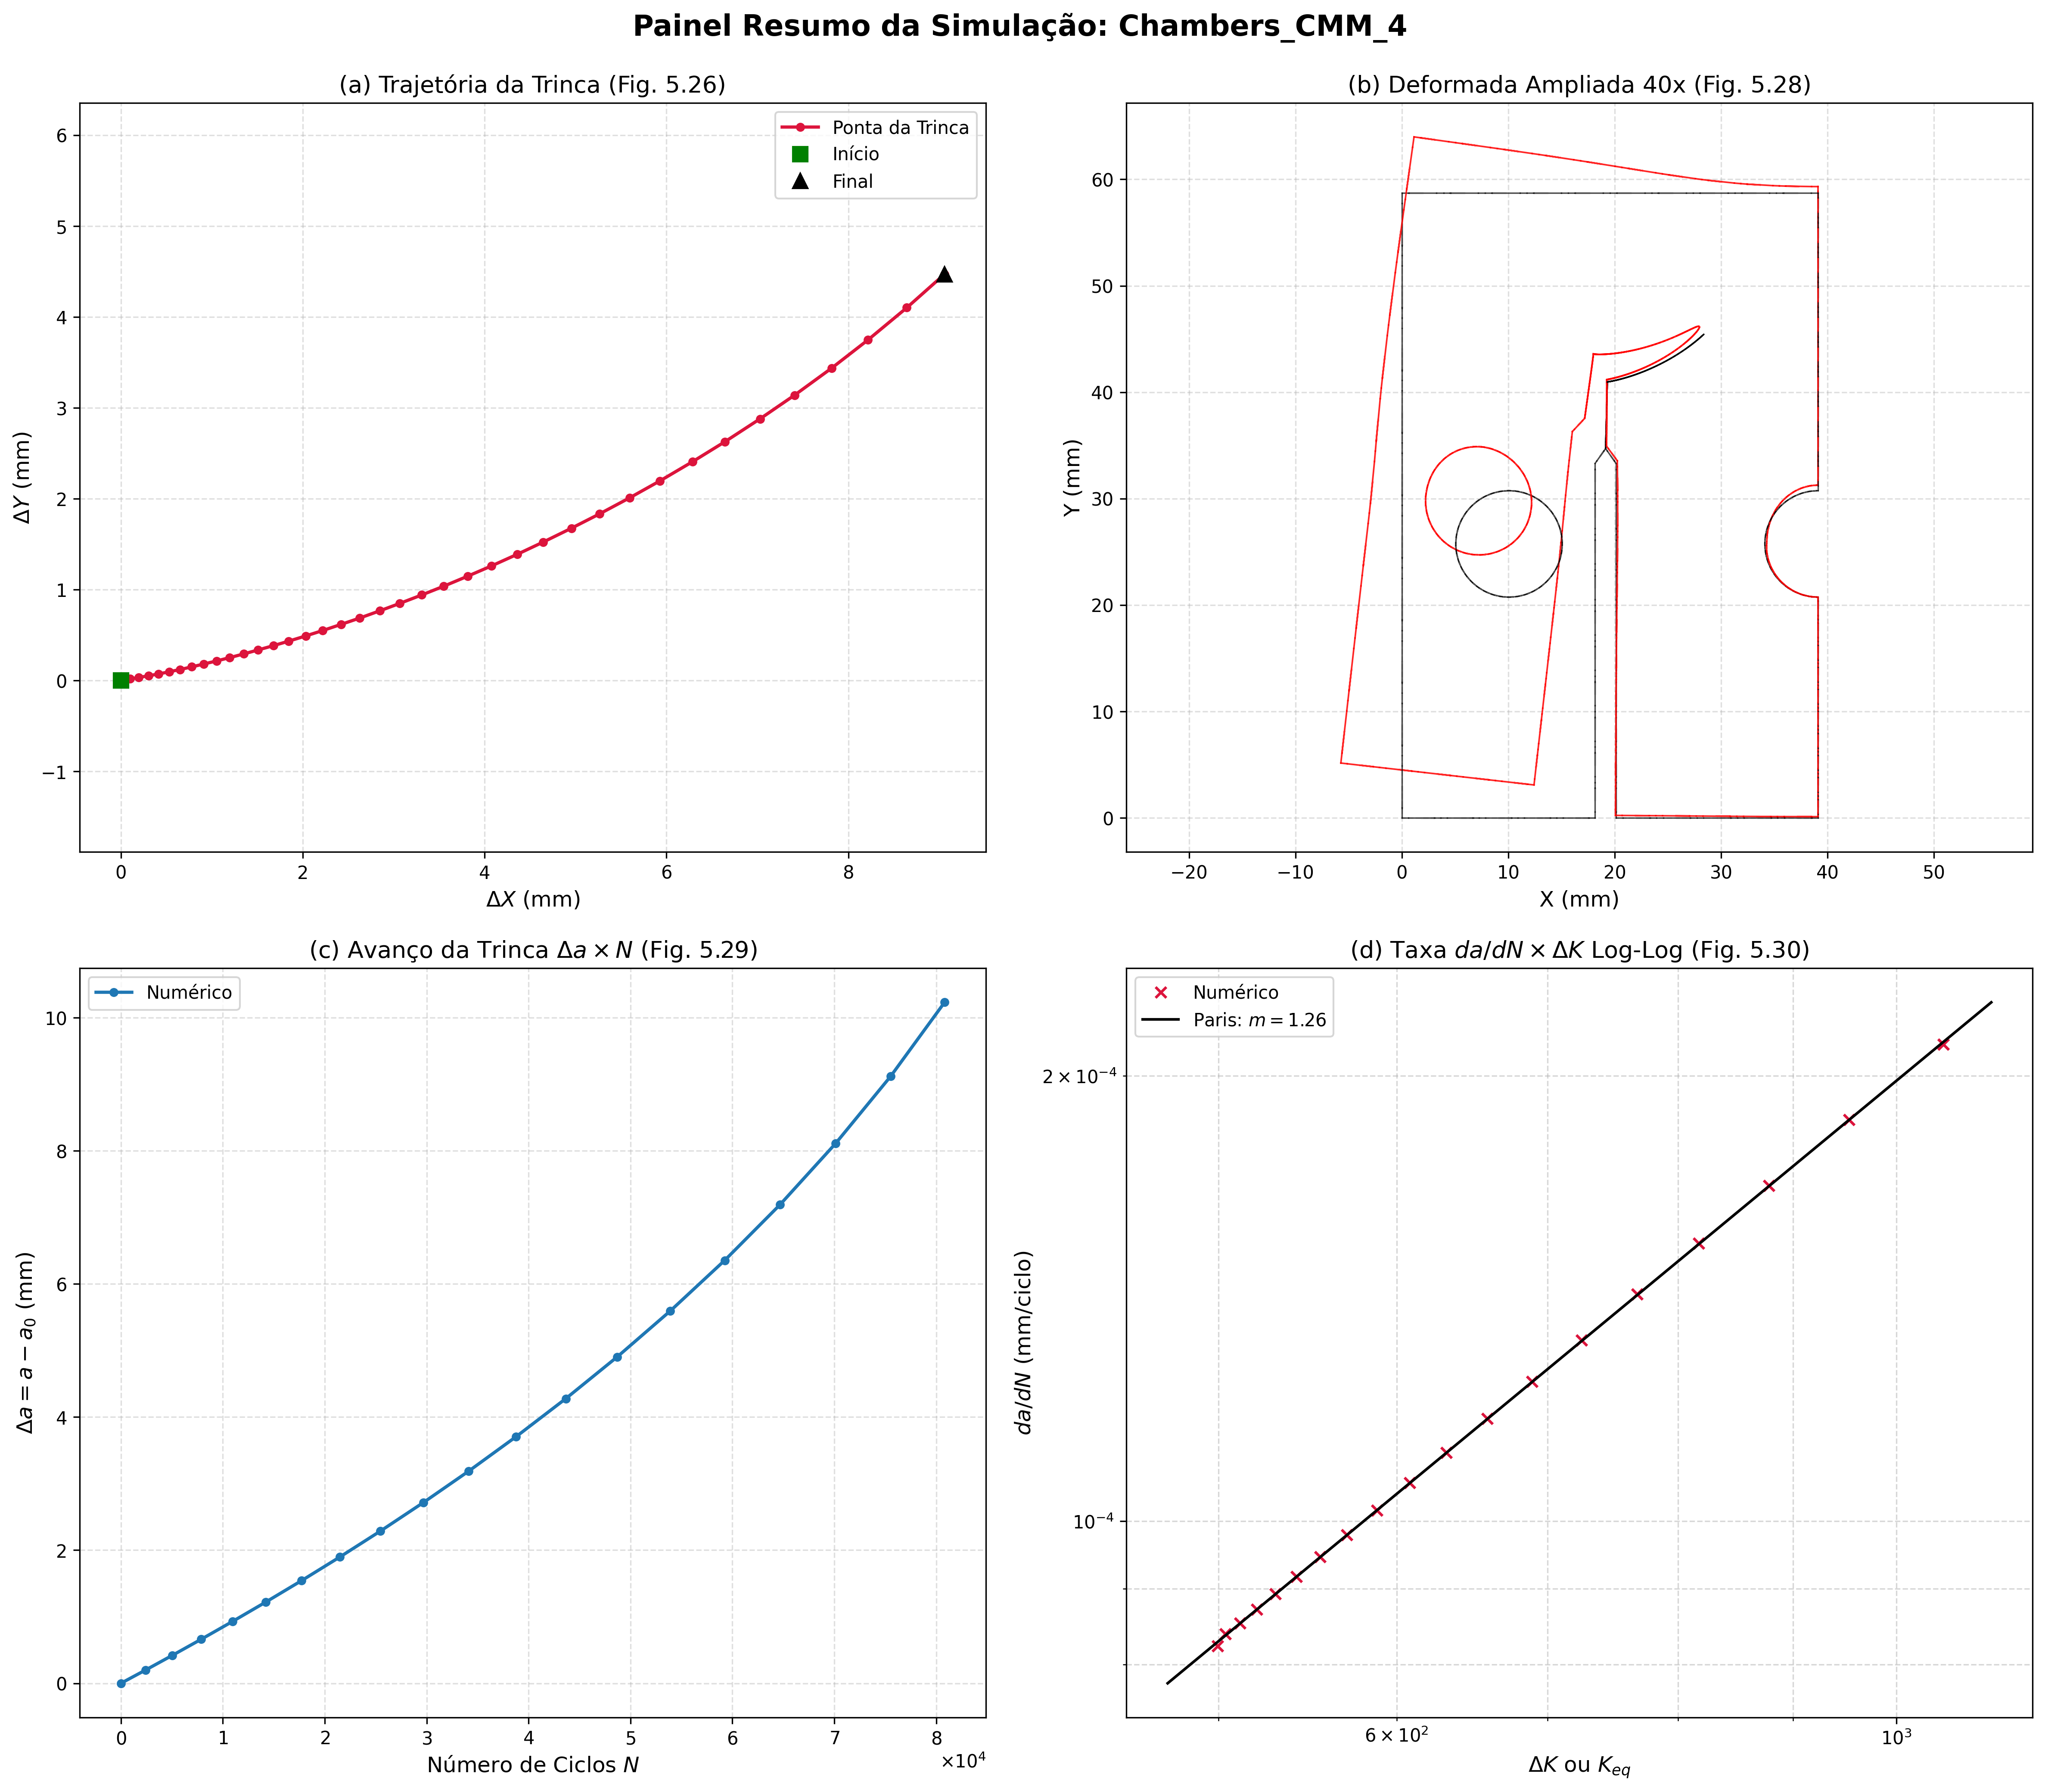

In [10]:
examples_dir = ROOT_DIR / "examples"
subprocess.run(
    [sys.executable, str(ROOT_DIR / "plot_results.py"), str(res_dir_cmm4), "--output-dir", str(examples_dir), "--scale", "40"],
    check=True
)

# Exibe as figuras geradas inline no notebook
figs_cmm4 = [
    ("Figura 5.26 — Trajetória de Propagação da Trinca (CMM4)", "Chambers_CMM_4_fig526_trajetoria.png"),
    ("Figura 5.27 — Configuração Final da Malha no Passo 38 (CMM4)", "Chambers_CMM_4_fig527_malha_final.png"),
    ("Figura 5.28 — Configuração Deformada Ampliada 40x (CMM4)", "Chambers_CMM_4_fig528_deformada_40x.png"),
    ("Figura 5.29 — Avanço da Trinca vs Número de Ciclos (CMM4)", "Chambers_CMM_4_fig529_ciclos_vs_trinca.png"),
    ("Figura 5.30 — Taxa de Propagação da/dN vs Delta K (CMM4)", "Chambers_CMM_4_fig530_dadn_vs_dK.png"),
    ("Evolução de K_I, K_II e K_eq ao Longo da Propagação (CMM4)", "Chambers_CMM_4_sif_evolucao.png"),
    ("Painel Resumo Integrado 2x2 (CMM4)", "Chambers_CMM_4_dashboard_resumo.png"),
]

for titulo, fname in figs_cmm4:
    fpath = examples_dir / fname
    if fpath.exists():
        print(f"\n=== {titulo} ===")
        display(Image(filename=str(fpath), width=760))

### Visualização de Fadiga sob Amplitude Variável e Contagem Rainflow (`Dowling_11.6_variable_ampl`)

Para carregamentos de amplitude variável (Seção 5.2.3 da dissertação — Exemplo 11.6 de Dowling), o módulo `fatigue_prop_mod.f90` executa o algoritmo **Rainflow Cycle Counting** sobre a história de picos e vales, extraindo os 166 ciclos $(\alpha_{\max}, R)$ em `<id>_cycles.txt` e determinando a tensão equivalente de Walker. Abaixo exibimos o espectro Rainflow e o painel resumo gerados para esse caso:


=== Espectro de Ciclos Rainflow (Dowling 11.6) ===

=== Painel Resumo — Amplitude Variável (Dowling 11.6) ===


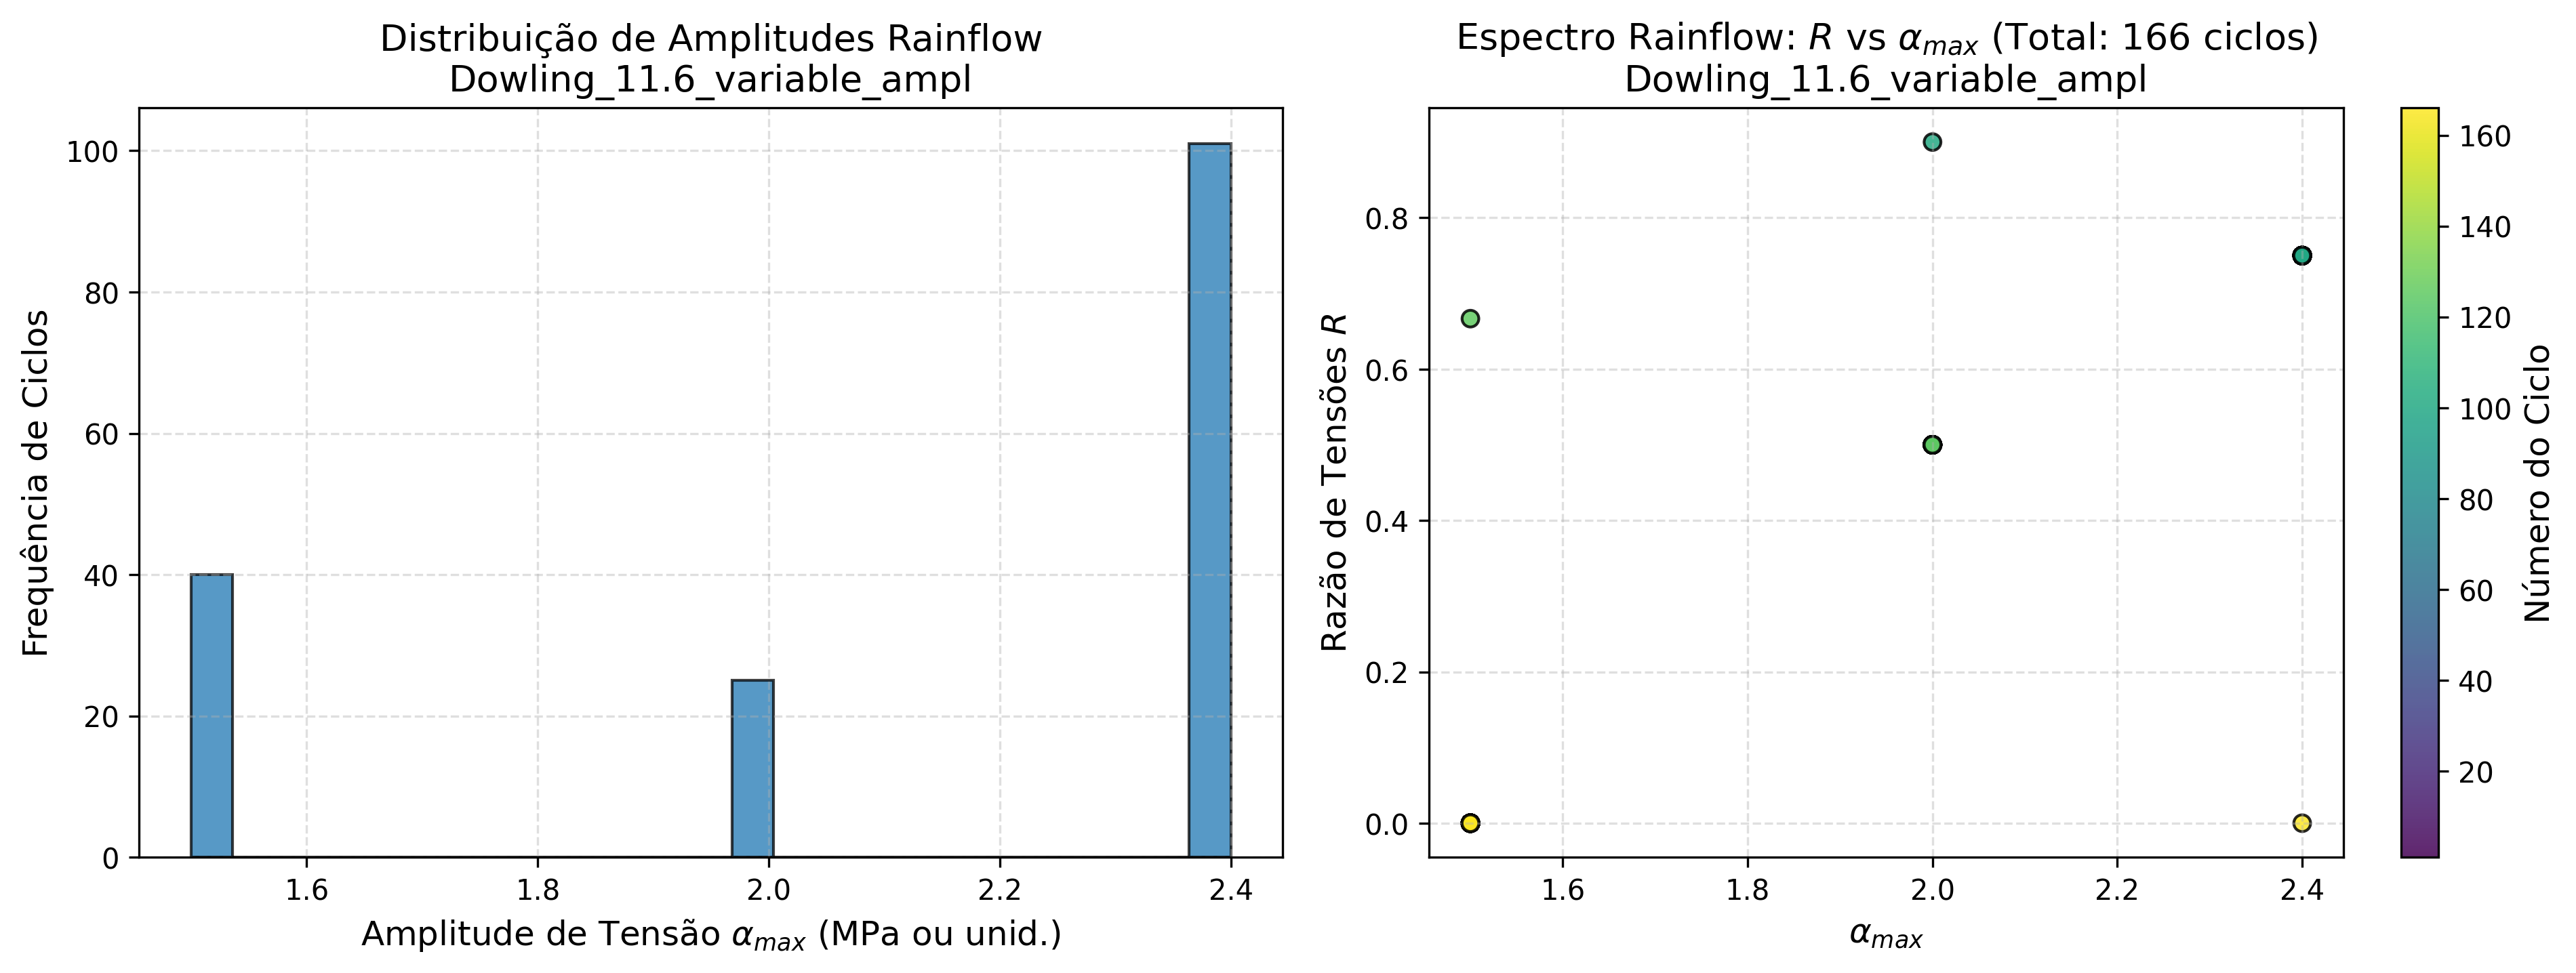

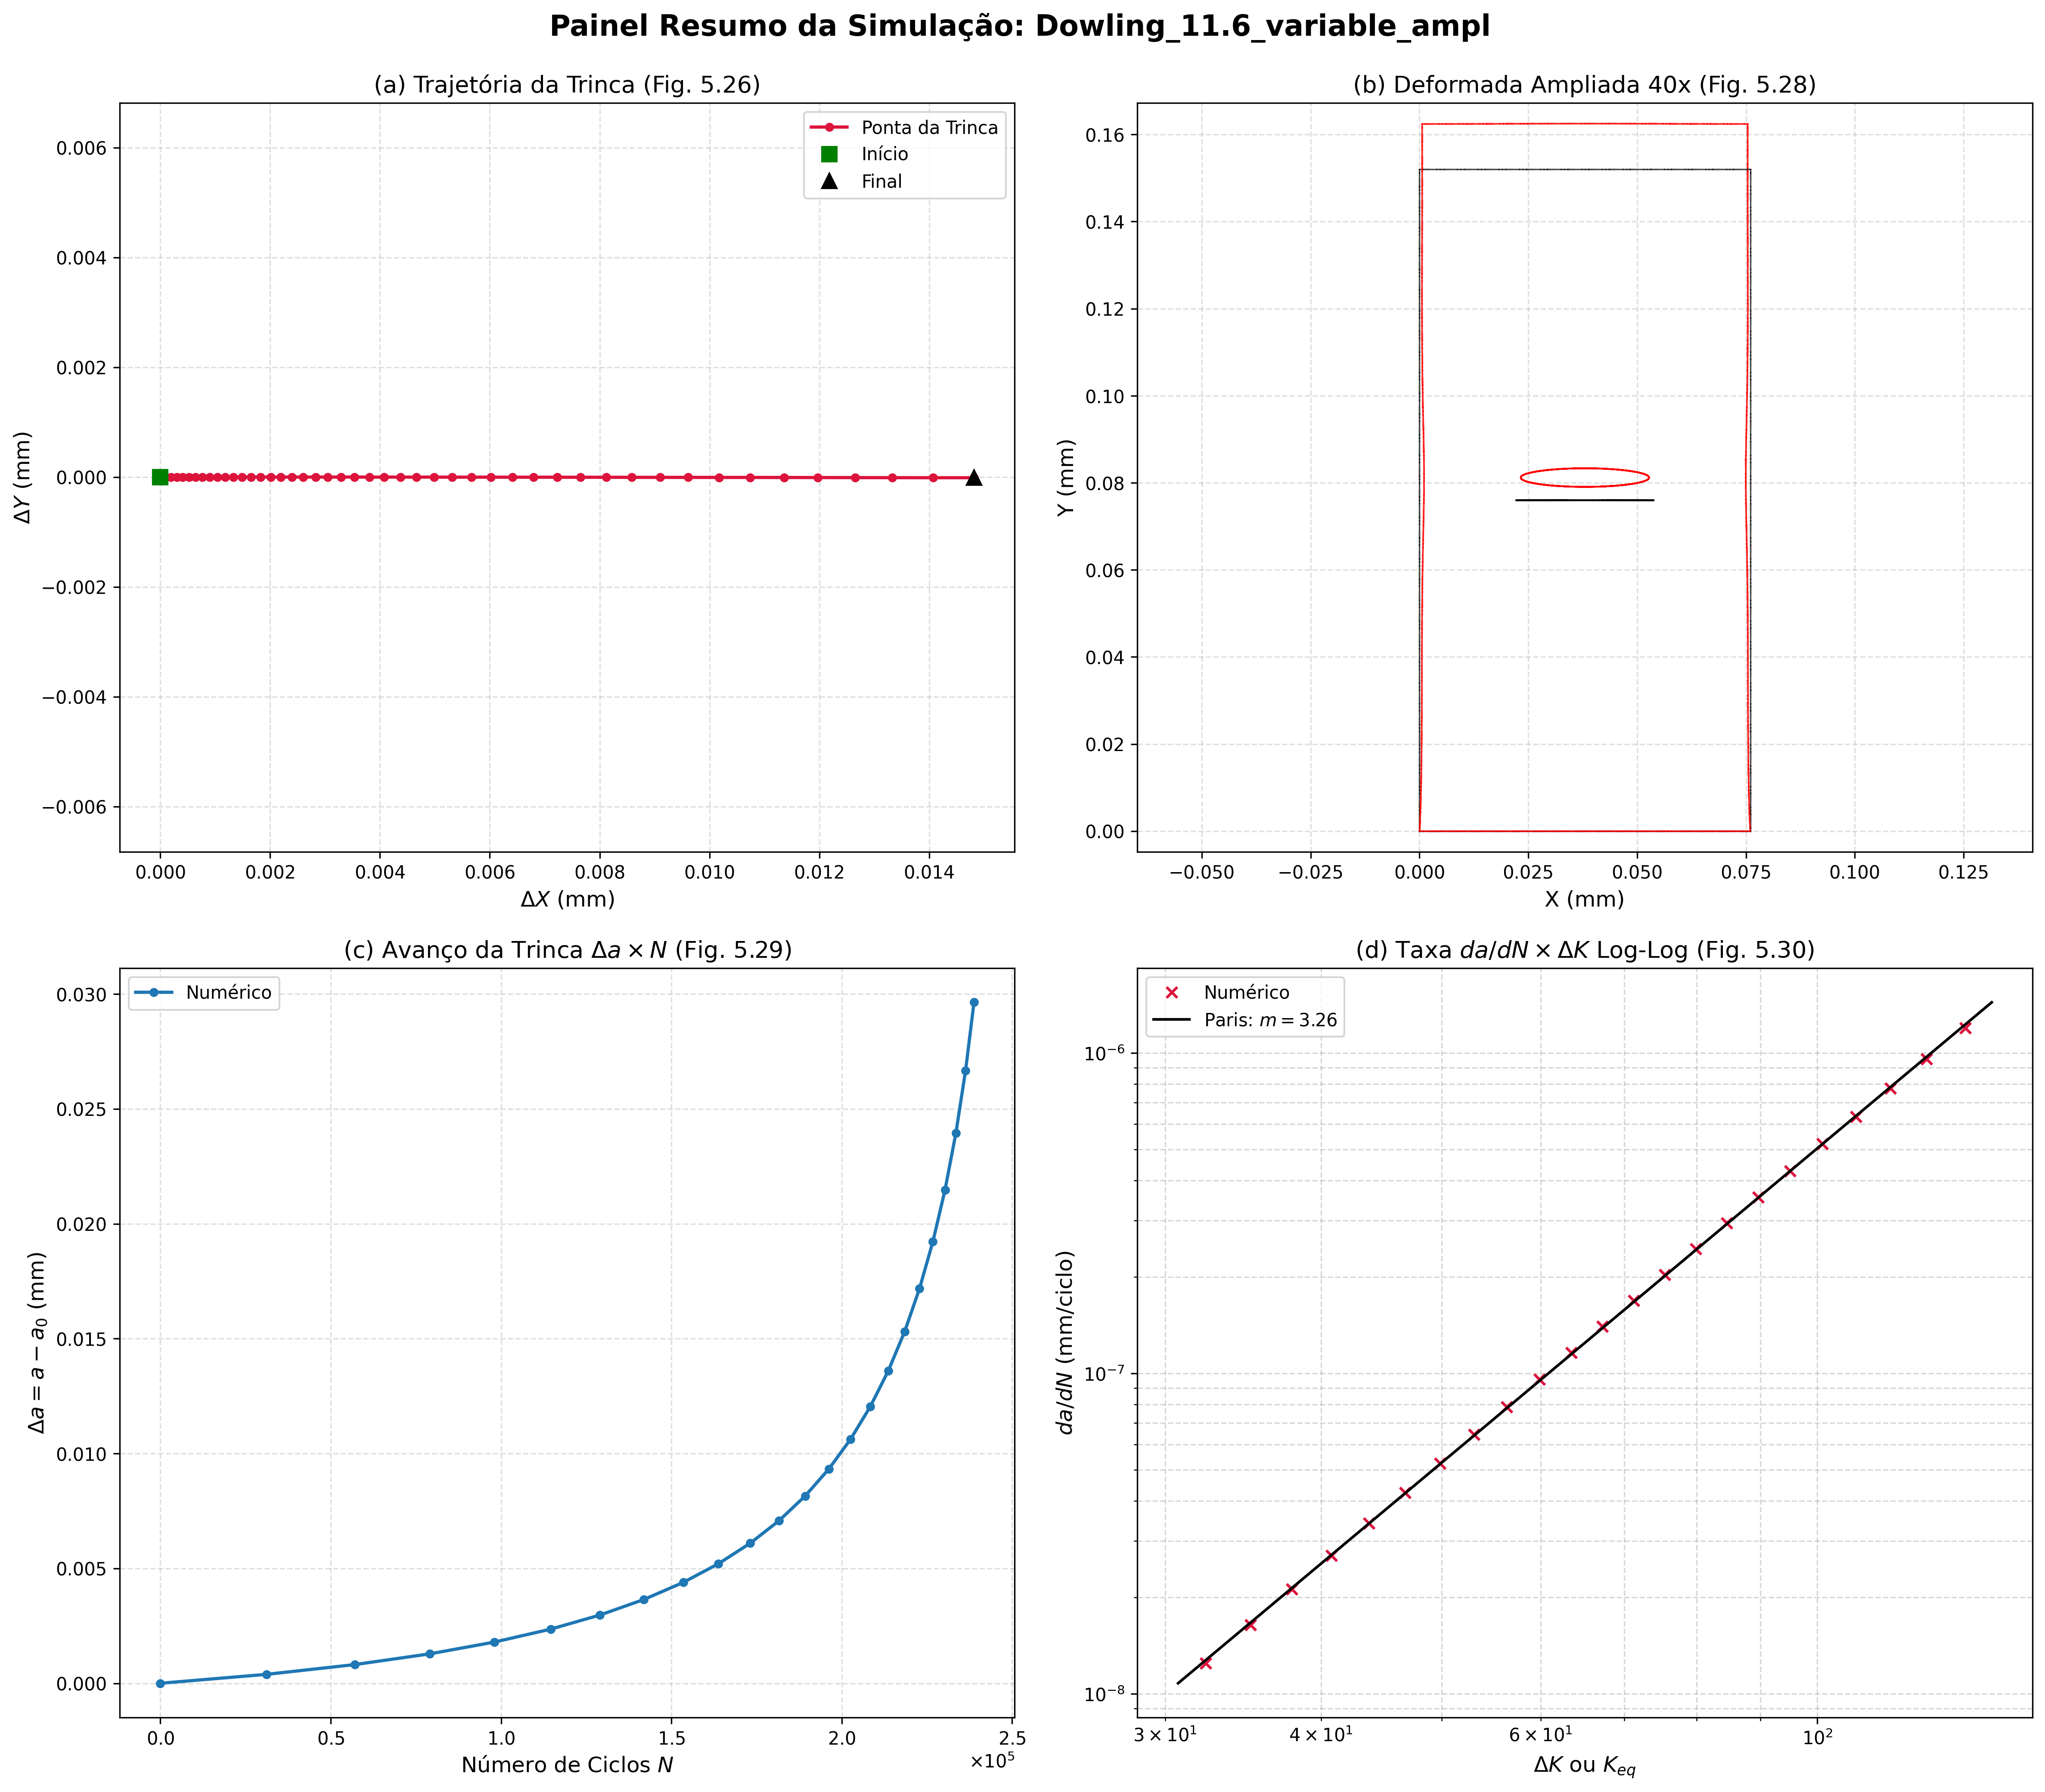

In [11]:
for titulo, fname in [
    ("Espectro de Ciclos Rainflow (Dowling 11.6)", "Dowling_11.6_variable_ampl_rainflow_ciclos.png"),
    ("Painel Resumo — Amplitude Variável (Dowling 11.6)", "Dowling_11.6_variable_ampl_dashboard_resumo.png"),
]:
    fpath = examples_dir / fname
    if fpath.exists():
        print(f"\n=== {titulo} ===")
        display(Image(filename=str(fpath), width=760))

## 9. Quadro-Resumo de Validação de Todos os Exemplos da Dissertação

Todos os 16 casos de teste dos Capítulos 3 e 5 da dissertação podem ser executados de uma só vez pelo script `python run_all_examples.py`. A tabela abaixo resume a validação obtida com o novo framework de elementos quadráticos descontínuos:

| Seção | Problema / Geometria | Resultado Obtido (Dual-BEM Descontínuo) | Referência Analítica / Dissertação | Erro / Diferença |
|---|---|---|---|---|
| **3.1.3.1** | Trinca de borda ($a/w = 0,2 \dots 0,6$) | $K_{I,\text{norm}} = 1,487;\; 1,848;\; 2,323;\; 3,006;\; 4,140$ | Civelek & Erdogan: $1,488;\; 1,848;\; 2,324;\; 3,010;\; 4,152$ | **`-0,01%` a `-0,29%`** |
| **3.1.3.2** | Trinca central inclinada $45^\circ$ ($2a/w = 0,2 \dots 0,6$) | $K_{I,\text{norm}} = 0,520 \dots 0,667$ / $K_{II,\text{norm}} = 0,513 \dots 0,573$ | Murakami: $0,518 \dots 0,661$ / $0,507 \dots 0,567$ | **`+0,41%` a `+1,20%`** |
| **5.1 (a)** | Trinca central Isida ($\Delta a_0 = 0,01;\; r = 1,10$) | $2a_f = 0,9554$, $N_f = 229\,281,6$ ciclos | Eq. (5.4): $229\,938,9$ ciclos | **`-0,29%`** |
| **5.1 (b)** | Trinca central Isida ($\Delta a_0 = 0,0125;\; r = 1,05$) | $2a_f = 0,8959$, $N_f = 228\,756,3$ ciclos | Eq. (5.4): $229\,311,9$ ciclos | **`-0,24%`** |
| **5.2.1** | Placa AISI 4340 — 1 trinca de borda | $a_f = 12,232\text{ mm}$, $N_f = 25\,819,8$ ciclos | Analítico: $25\,070,4$ ciclos | **`+2,99%`** |
| **5.2.2** | Placa AISI 4340 — 2 trincas de borda | $a_f = 15,281\text{ mm}$, $N_f = 54\,324,8$ ciclos | Analítico: $53\,457,6$ ciclos | **`+1,62%`** |
| **5.2.3** | Amplitude variável (`Dowling 11.6`) | $2a_f = 31,637\text{ mm}$, $K_{\max,f} = 131,38$, $N_f = 238\,810,1$ | Feddersen: $131,69$ / Diss.: $238\,810,1$ | **`-0,24%` em $K_I$ / `0,00%` em $N_f$** |
| **5.3.1** | CMM $\alpha = 90^\circ$ (CMM1 / CMM2 / CMM3) | $N = 68\,958,4 \; / \; 43\,893,0 \; / \; 38\,979,4$ ciclos | Diss.: $66\,550 \; / \; 42\,508 \; / \; 38\,059$ | **`+2,42%` a `+3,62%`** |
| **5.3.2** | CMM4 $\alpha = 110^\circ$ ($\Delta a = 2,7\text{ mm}$) | $N = 29\,524,5$ ciclos ($K_{II,0}=401,1 \to K_{II,1}=1,54$) | Diss.: $28\,783$ (Exp.: $27\,782$) | **`+2,58%`** |

---

## 10. Guia Prático para o Aluno: Como Criar Seu Próprio Problema

Para modelar e simular uma nova geometria com uma ou mais trincas:
1. **Crie o arquivo `.geo` na pasta `meshes/`**:
   - Defina os pontos (`Point`), linhas (`Line`) ou arcos (`Circle`) do contorno externo e das trincas;
   - Caso seja uma trinca de borda, divida a aresta externa no ponto de abertura da trinca;
   - Associe nomes aos grupos físicos (`Physical Curve("TOPO") = ...`, `Physical Curve("crack") = ...`).
2. **Adicione seu caso na função `input_data(problem)` em `input_data.py`**:
   - Informe `E`, `nu`, `plane_state`, as condições de contorno de cada `Physical Curve` em `'bound_cond'`, a lista `'cracks'` (`'tips': 1` para borda ou `'tips': 2` para interna) e os parâmetros de `'fatigue'`.
3. **Gere o arquivo `.dat` e verifique a malha**:
   ```bash
   python preproc.py meu_novo_caso
   ```
   Inspecione a figura `inputs/meu_novo_caso_mesh_bc.png` para confirmar se os apoios (vermelho), cargas (azul) e faces da trinca (laranja) estão corretos.
4. **Rode o solver e gere os gráficos**:
   ```bash
   ./bin/fracture_2d.exe inputs/meu_novo_caso.dat
   python plot_results.py . --output-dir examples
   ```